# Toy MC — две группы фона

Копия `toy_mc.ipynb`. Каты, входные данные и фит сохранены. Маркеры 2–6 объединены в wrong tag (`ubs`), маркер 1 — Bs → D(ℓν)ℓν. Цвета из `source.colors`: wrong tag — colors[0] с прозрачностью 0.55, сигнал — colors[1], Bs → D(ℓν)ℓν — colors[3]. Графики сохраняются с префиксом `two_bg_`.


In [27]:
from bdt_header import (
    np, pd, ds, plt, Path, json, colors, PLOT_COLORS, PLOT_CMAPS, XGBClassifier,
    get_values, hist_approx, normalization, Bs_m,
    mask_physics, mask_lep, mask_mc_signal, mask_mc_tag, mask_mc_wrong_tag,
)

plt.rcParams["figure.figsize"] = (12/1.5, 6/1.5)

# Только пути к существующим ресурсам; файлы не изменяются.
resources = {
    "model": Path("models/bdt_model_lep.json"),
    "bdt": Path("models/columns_and_fom_lep.json"),
    "efficiency": Path("results/data_lep.json"),
    "signal": Path("shapes/sig_lep.json"),
    "bsbs": Path("shapes/bg_bsbs_lep.json"),
    "ubs": Path("shapes/bg_ubs_lep.json"),
    "counts": Path("quantity/N_lep.json"),
}
# Справочная эффективность: исходный фит определяет N_sig, а не ветвление.
with resources["efficiency"].open(encoding="utf-8") as f:
    efficiency_info = json.load(f)


In [28]:
bsbs = ds.dataset(list(Path(f"gen_data/").glob("bsbs*.parquet")), format="parquet")
nonbsbs = ds.dataset(list(Path(f"gen_data/").glob("nonbsbs*.parquet")), format="parquet")
uds = ds.dataset(list(Path(f"gen_data/").glob("uds*.parquet")), format="parquet")


In [29]:
# Все части отбора определены в bdt_header.py.
mask_sig = mask_lep & mask_mc_tag & mask_mc_signal & mask_physics
mask_bkg = mask_lep & mask_mc_tag & mask_physics
mask_bkg_wrong_tag = mask_lep & mask_mc_wrong_tag & mask_physics


In [30]:
model = XGBClassifier()
model.load_model(resources["model"])
with resources["bdt"].open(encoding="utf-8") as f:
    data_to_save = json.load(f)
columns = data_to_save["columns"]
FoM = float(data_to_save["FoM"]["lep"])


In [31]:
v1 = get_values(bsbs, columns + ['E_gamma_in_ROE', 'MBtag'], filter_mask=mask_bkg)
v2 = get_values(nonbsbs, columns + ['E_gamma_in_ROE', 'MBtag'], filter_mask=mask_bkg)
v3 = get_values(uds, columns + ['E_gamma_in_ROE', 'MBtag'], filter_mask=mask_bkg)
v4 = get_values(uds, columns + ['E_gamma_in_ROE', 'MBtag'], filter_mask=mask_bkg_wrong_tag)
v5 = get_values(nonbsbs, columns + ['E_gamma_in_ROE', 'MBtag'], filter_mask=mask_bkg_wrong_tag)
v6 = get_values(bsbs, columns + ['E_gamma_in_ROE', 'MBtag'], filter_mask=mask_bkg_wrong_tag)
v1["marker"] = 1  # $B_s \to D(\ell \nu)\ell \nu$
v2["marker"] = 2  # nonbsbs
v3["marker"] = 3  # continuum
v4["marker"] = 4  # B_s^{tag} \ rec. \ err.
v5["marker"] = 5  # B_s^{tag} \ rec. \ err.
v6["marker"] = 6  # B_s^{tag} \ rec. \ err.

data = pd.concat([v1, v2, v3, v4, v5, v6], ignore_index=True)

# Объединение только для отображения; исходные marker и отбор не меняются.
data["background_group"] = np.where(data["marker"] == 1, "bsbs", "ubs")
background_order = ("ubs", "bsbs")
background_labels = {
    "ubs": r"$B_s$ wrong tag / continuum",
    "bsbs": r"$B_s\to D(\ell\nu)\ell\nu$",
}


Total data size: 0.04 MB
Total data size: 0.00 MB
Total data size: 0.00 MB
Total data size: 0.00 MB
Total data size: 0.00 MB
Total data size: 0.02 MB


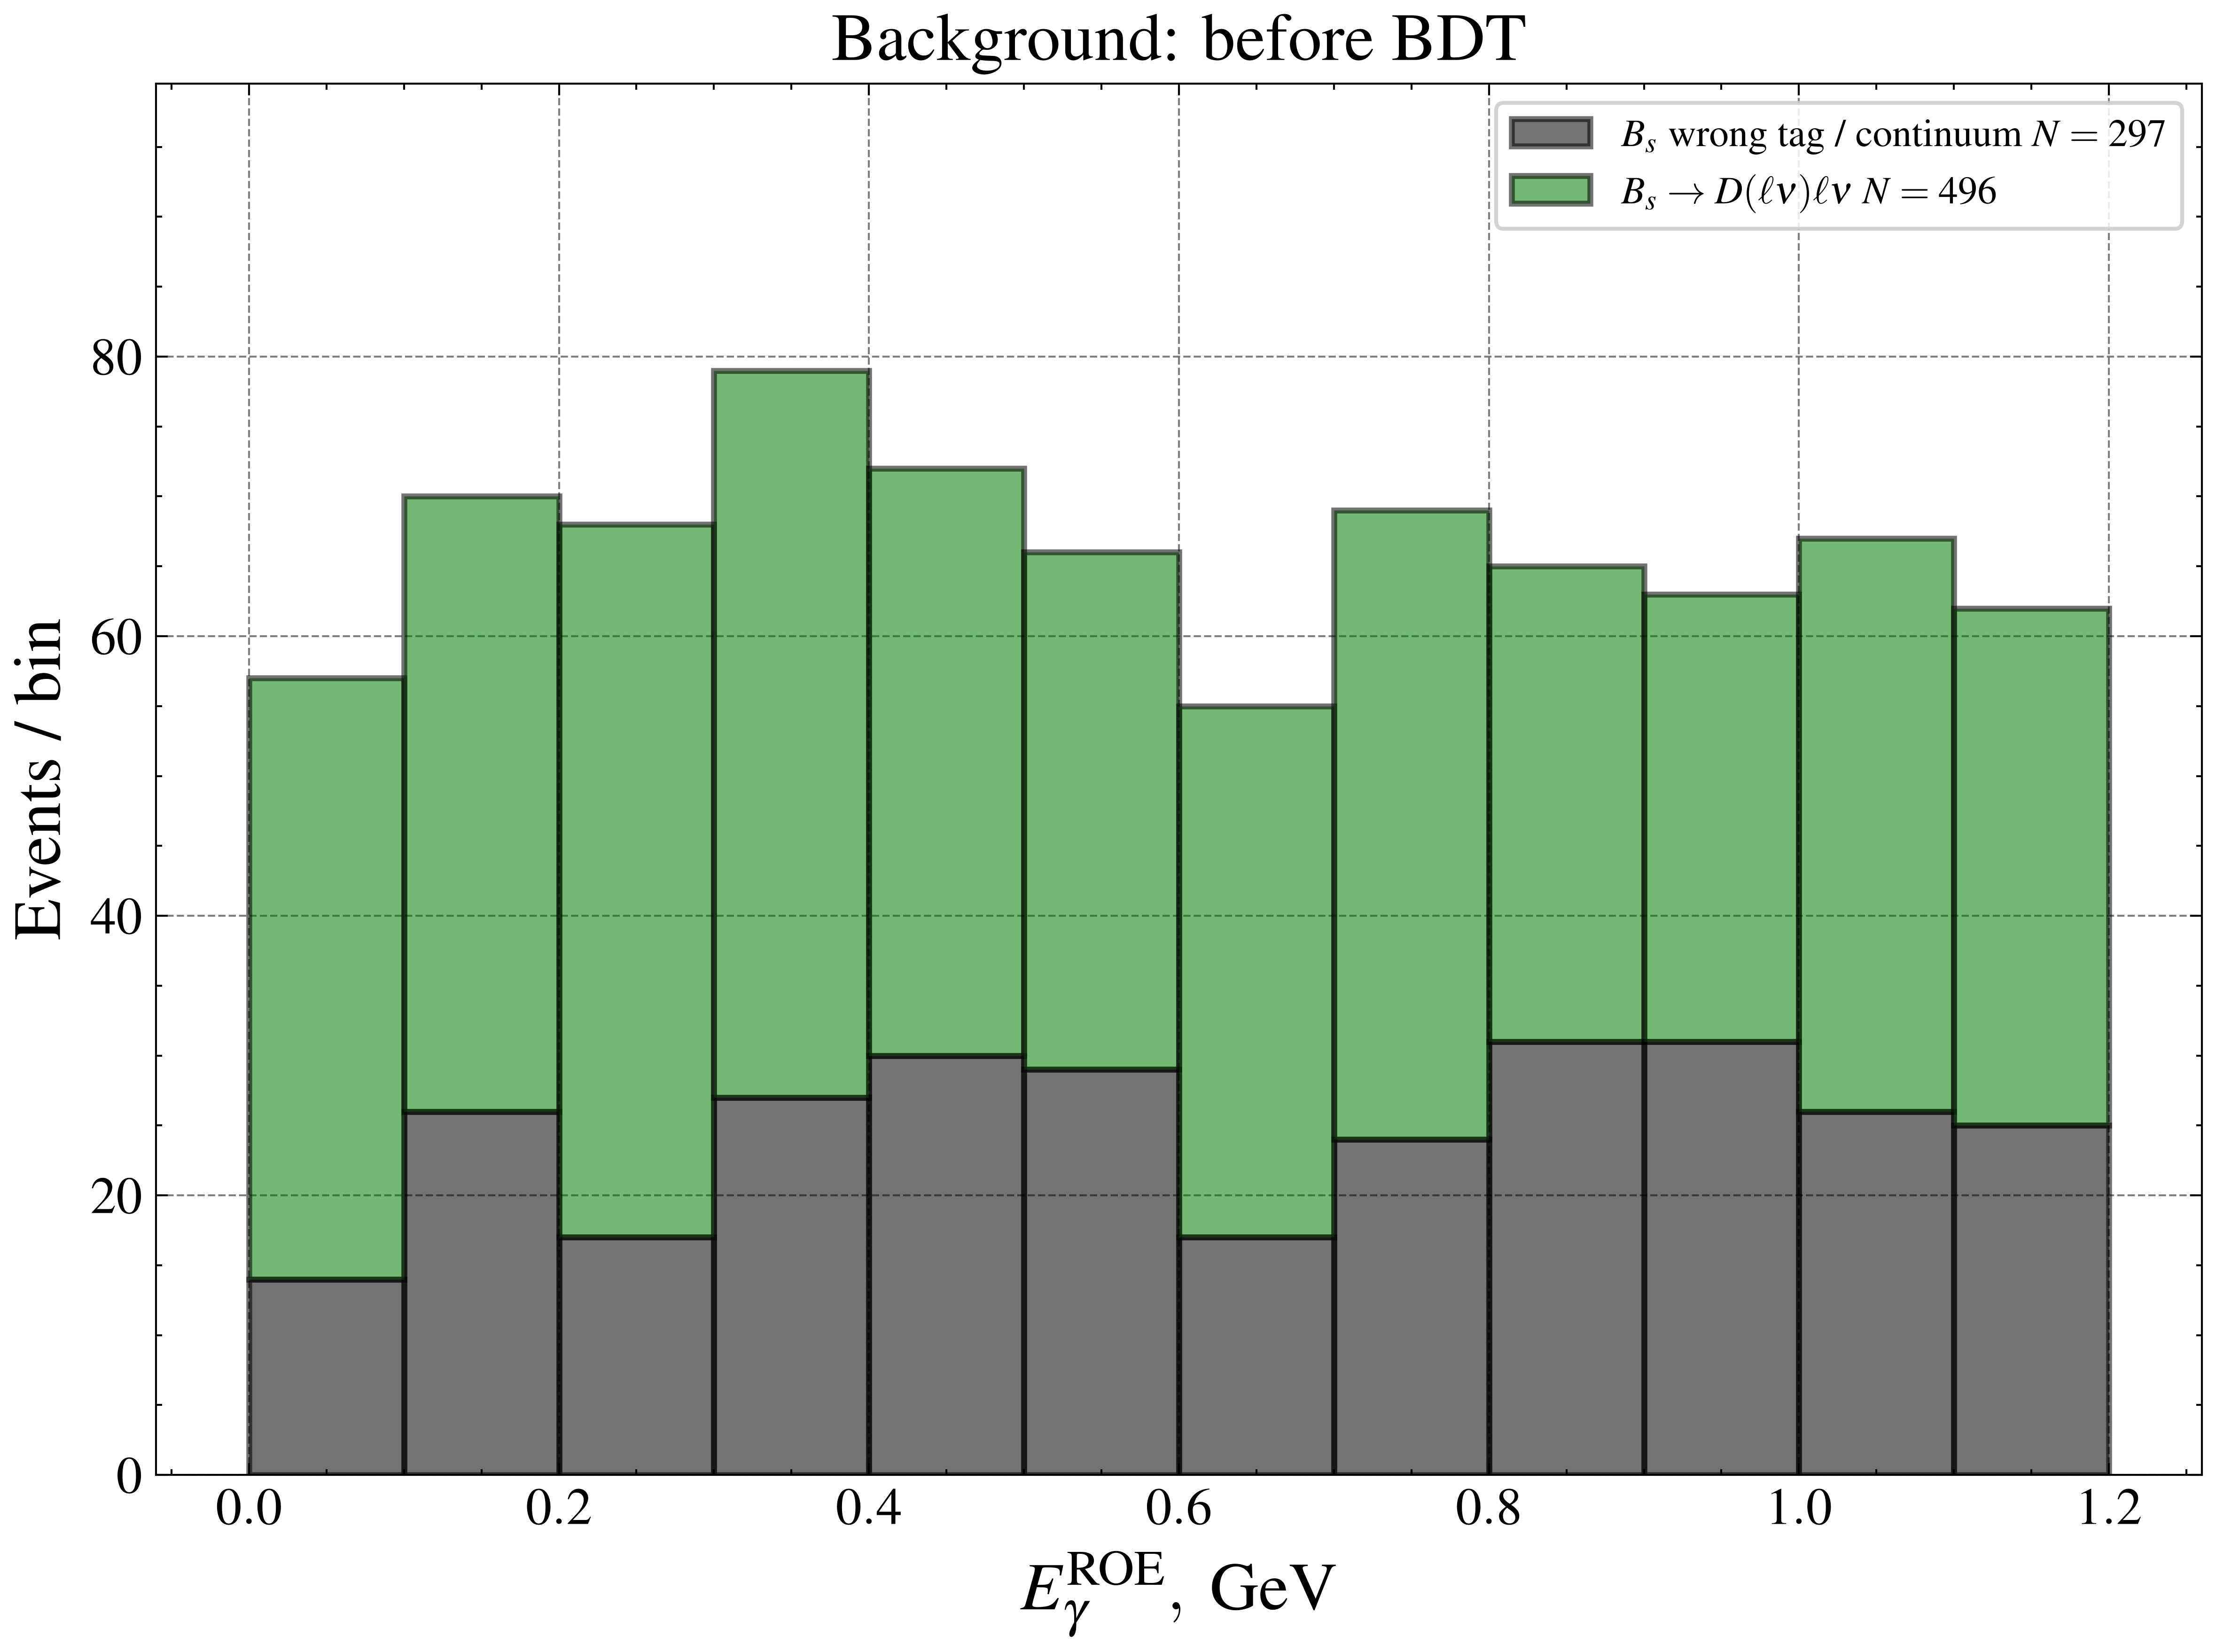

In [32]:
wbin = 0.1
a = 0
b = 1.2
bins = np.linspace(a, b, int((b - a) // wbin) + 2)

stack_data = []
stack_labels = []
for group in background_order:
    subset = data.loc[data["background_group"] == group, "E_gamma_in_ROE"]
    stack_data.append(subset)
    stack_labels.append(f"{background_labels[group]} $N = {len(subset)}$")

plt.figure(figsize=(8, 6))
plt.hist(stack_data, bins=bins, stacked=True, alpha=0.55,
         color=[PLOT_COLORS[group] for group in background_order],
         edgecolor="black", linewidth=1.5, label=stack_labels)
plt.xlabel(r"$E_\gamma^{\mathrm{ROE}}, \ \mathrm{GeV}$")
plt.ylabel("Events / bin")
plt.title("Background: before BDT")
plt.ylim(top=plt.ylim()[1] * 1.2)
plt.legend(loc="upper right", fontsize=10, framealpha=0.85)
plt.tight_layout()
plt.savefig("output/two_bg_bg_E_ROE_stack.pdf", dpi=700)
plt.show()


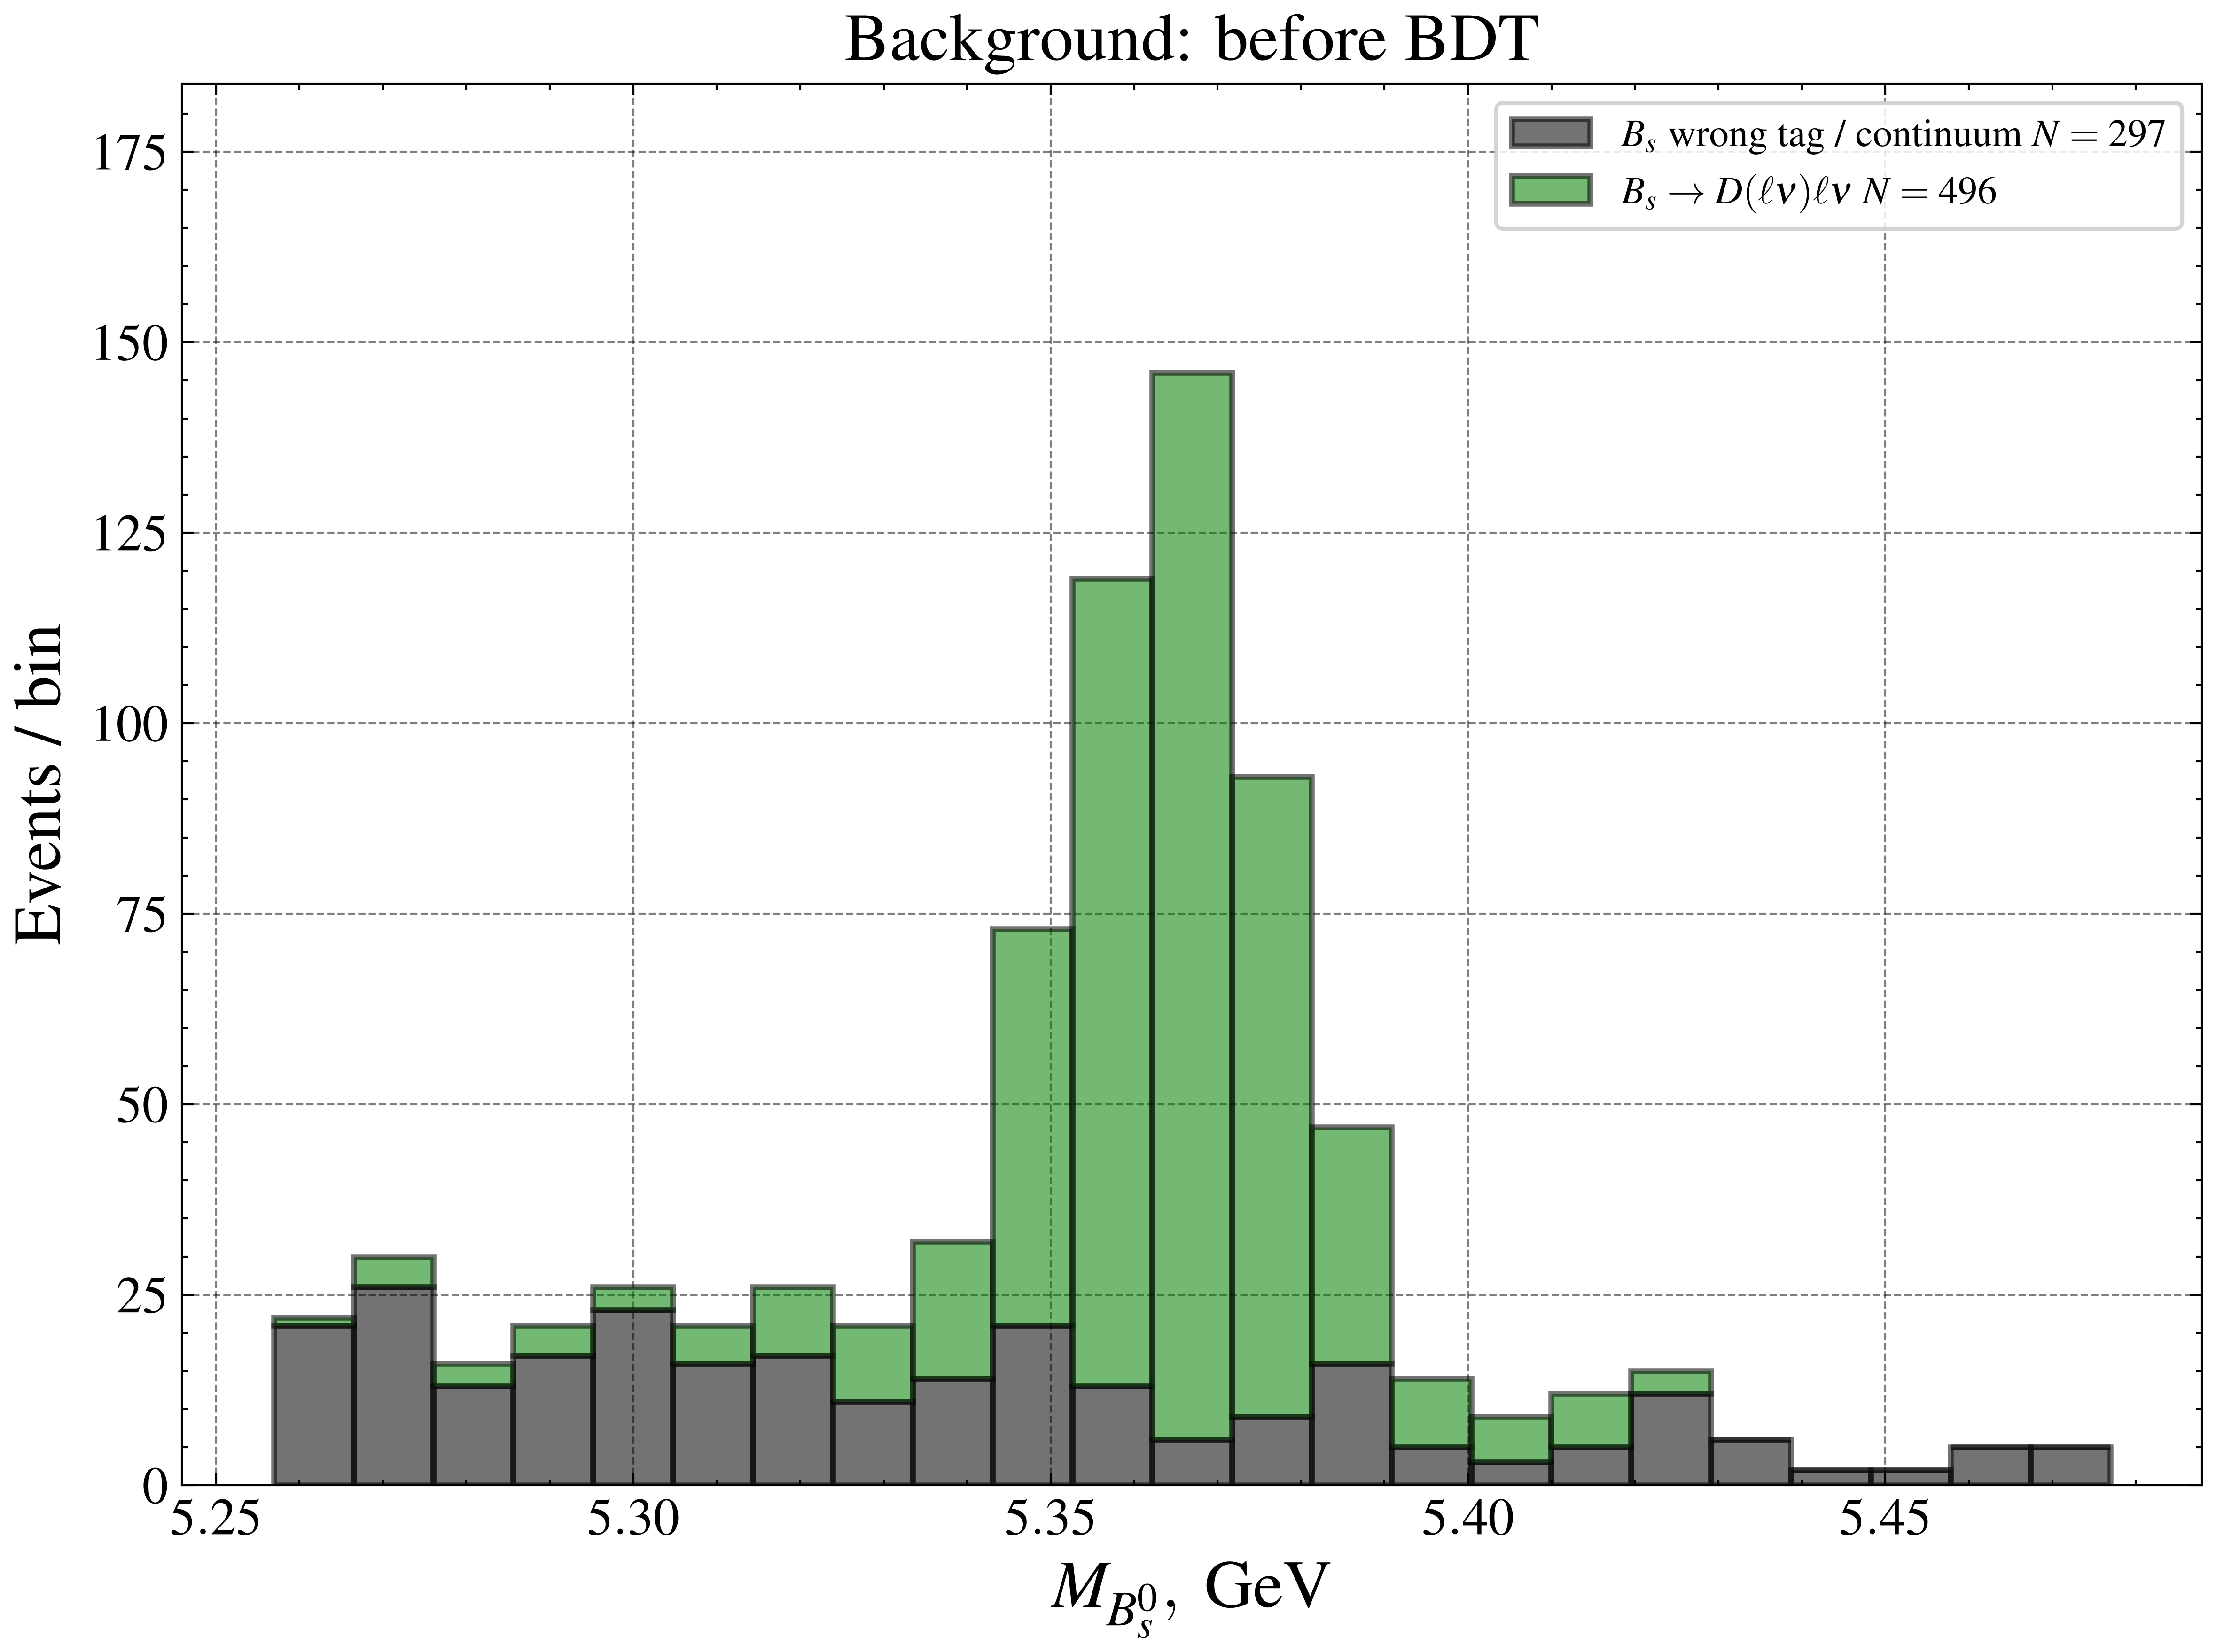

In [33]:
wbin = 0.01
a = Bs_m-0.11
b = Bs_m+0.11
bins = np.linspace(a, b, int((b - a) // wbin) + 2)

stack_data = []
stack_labels = []
for group in background_order:
    subset = data.loc[data["background_group"] == group, "MBtag"]
    stack_data.append(subset)
    stack_labels.append(f"{background_labels[group]} $N = {len(subset)}$")

plt.figure(figsize=(8, 6))
plt.hist(stack_data, bins=bins, stacked=True, alpha=0.55,
         color=[PLOT_COLORS[group] for group in background_order],
         edgecolor="black", linewidth=1.5, label=stack_labels)
plt.xlabel(r"$M_{B_s^0}, \ \mathrm{GeV}$")
plt.ylabel("Events / bin")
plt.title("Background: before BDT")
plt.ylim(top=plt.ylim()[1] * 1.2)
plt.legend(loc="upper right", fontsize=10, framealpha=0.85)
plt.tight_layout()
plt.savefig("output/two_bg_bg_M_BS0_stack.pdf", dpi=700)
plt.show()


In [34]:
X_new = data[columns]

bdt_scores = model.predict_proba(X_new)[:, 1] 

data["bdt_score"] = bdt_scores

selected_mask = data["bdt_score"] > FoM

selected_data = data[selected_mask]


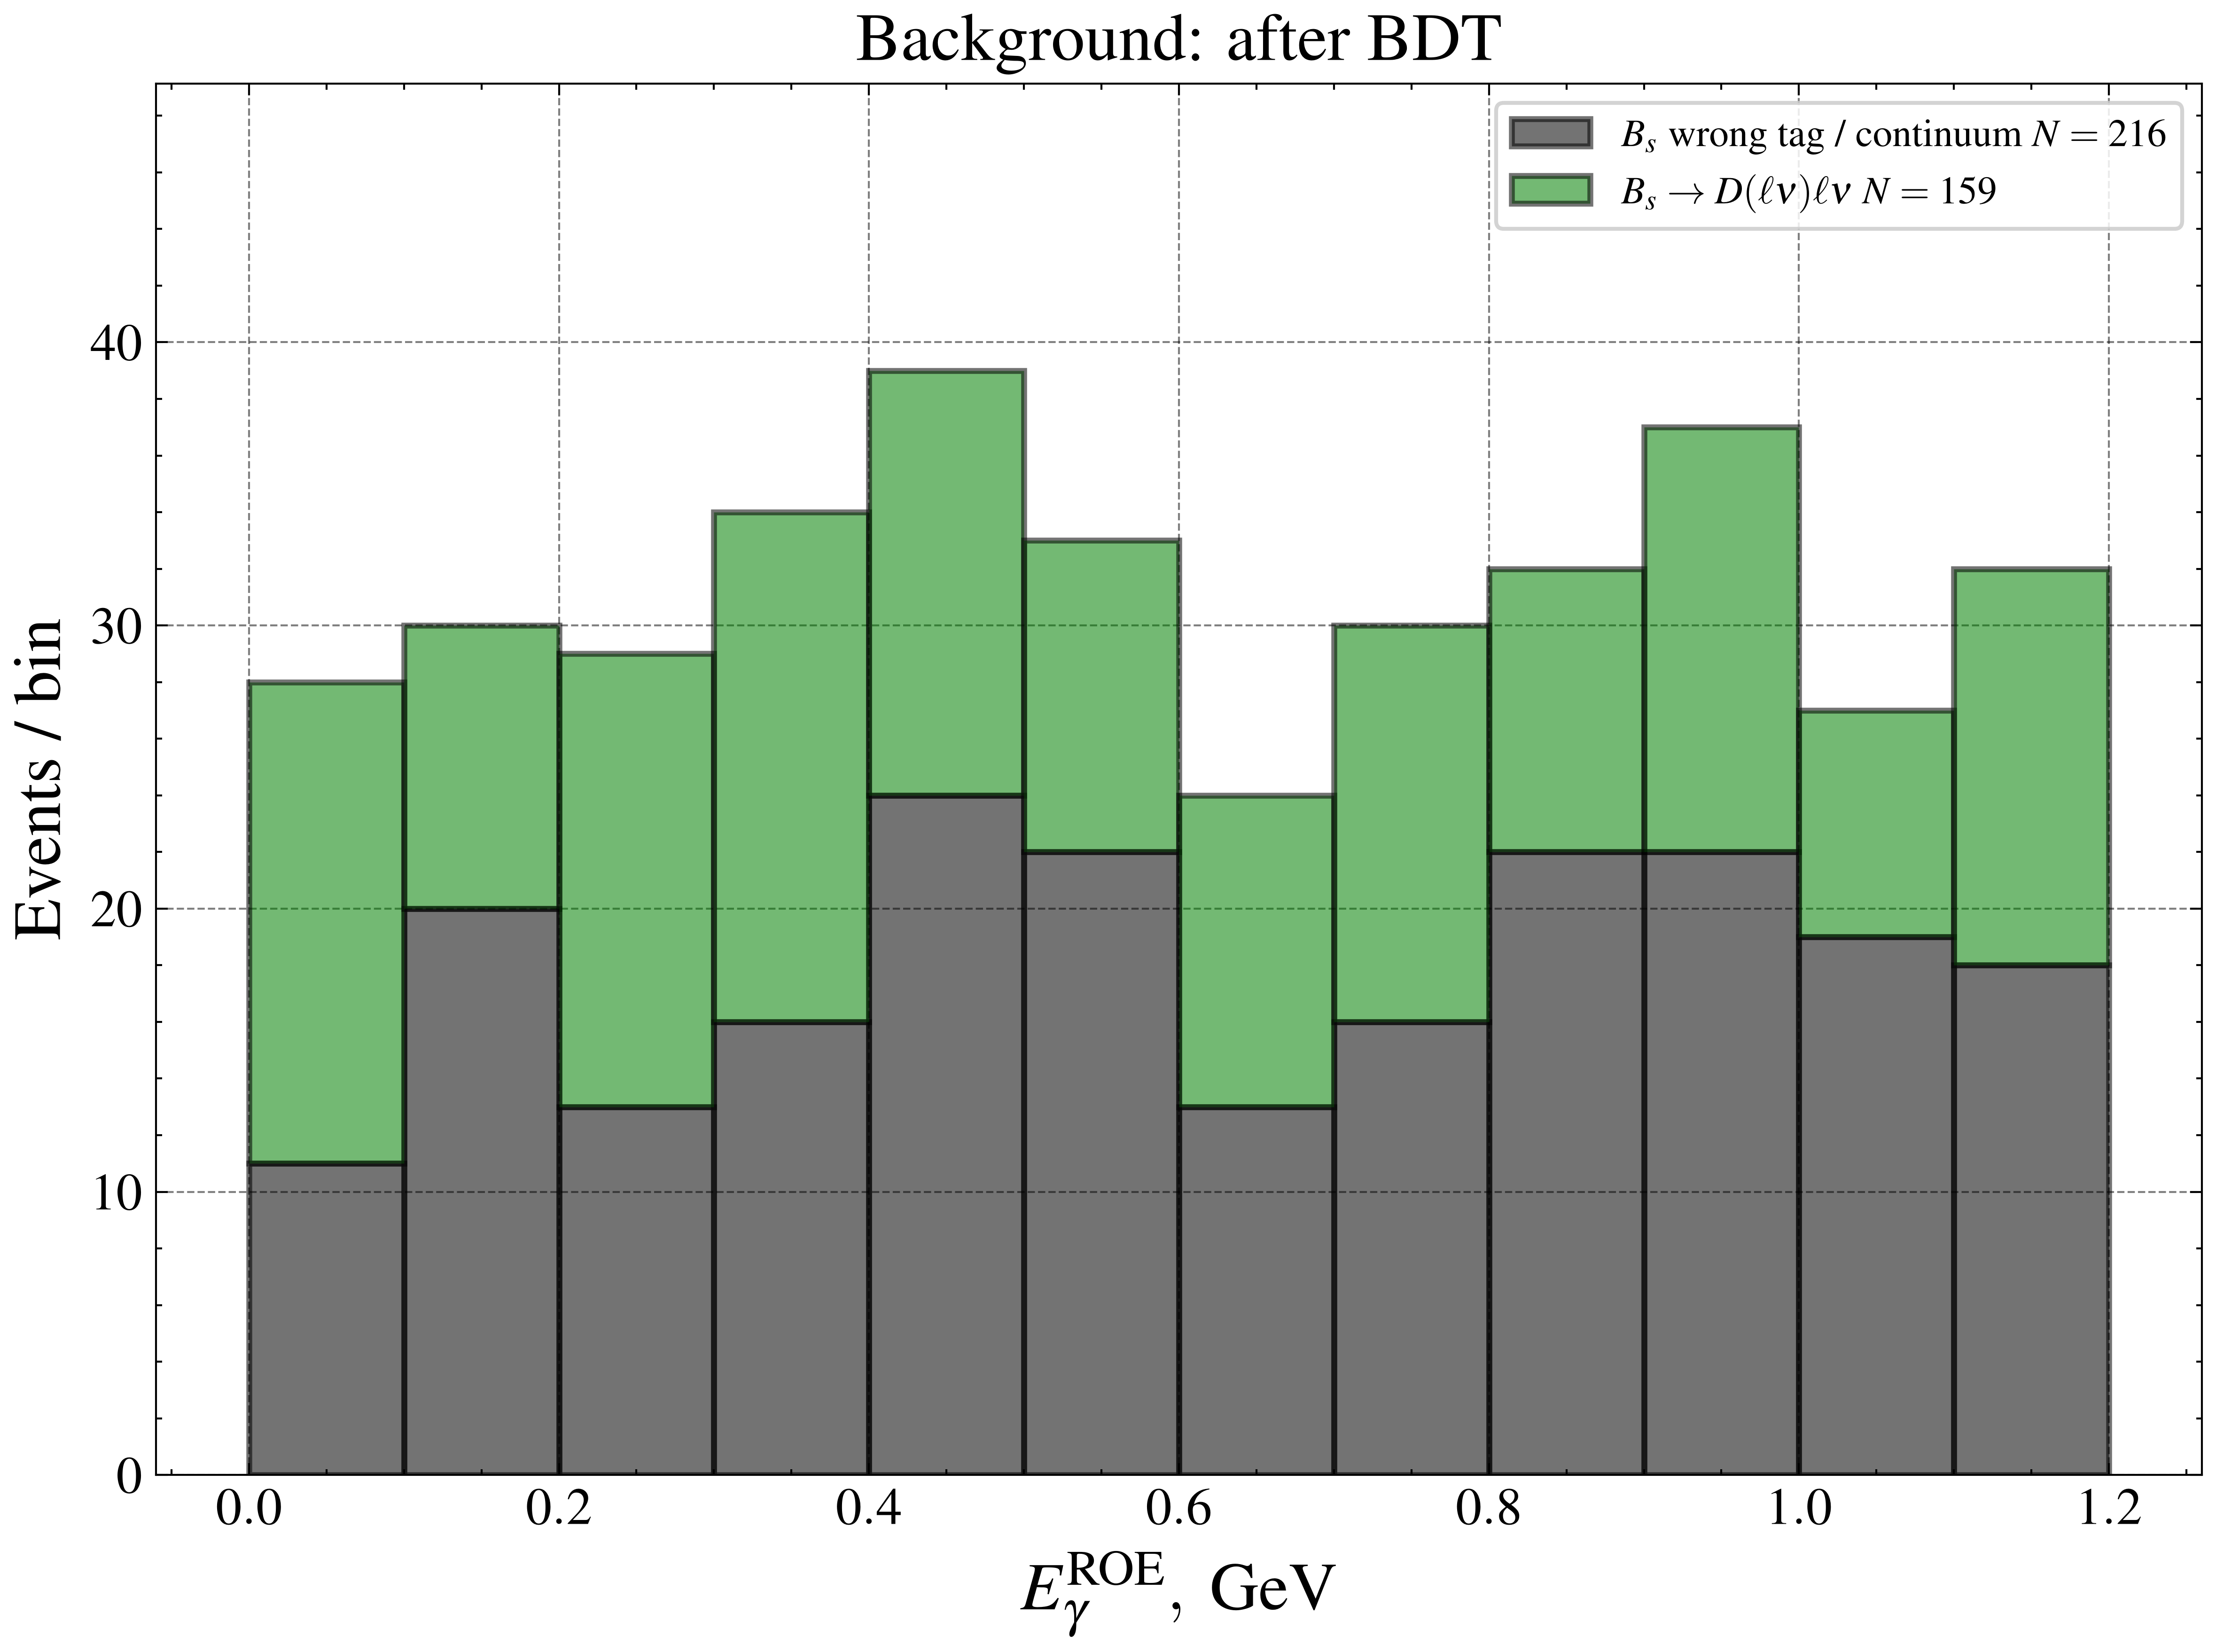

In [35]:
wbin = 0.1
a = 0
b = 1.2
bins = np.linspace(a, b, int((b - a) // wbin) + 2)

stack_data = []
stack_labels = []
for group in background_order:
    subset = selected_data.loc[selected_data["background_group"] == group, "E_gamma_in_ROE"]
    stack_data.append(subset)
    stack_labels.append(f"{background_labels[group]} $N = {len(subset)}$")

plt.figure(figsize=(8, 6))
plt.hist(stack_data, bins=bins, stacked=True, alpha=0.55,
         color=[PLOT_COLORS[group] for group in background_order],
         edgecolor="black", linewidth=1.5, label=stack_labels)
plt.xlabel(r"$E_\gamma^{\mathrm{ROE}}, \ \mathrm{GeV}$")
plt.ylabel("Events / bin")
plt.title("Background: after BDT")
plt.ylim(top=plt.ylim()[1] * 1.2)
plt.legend(loc="upper right", fontsize=10, framealpha=0.85)
plt.tight_layout()
plt.savefig("output/two_bg_BDT_bg_E_ROE_stack.pdf", dpi=700)
plt.show()


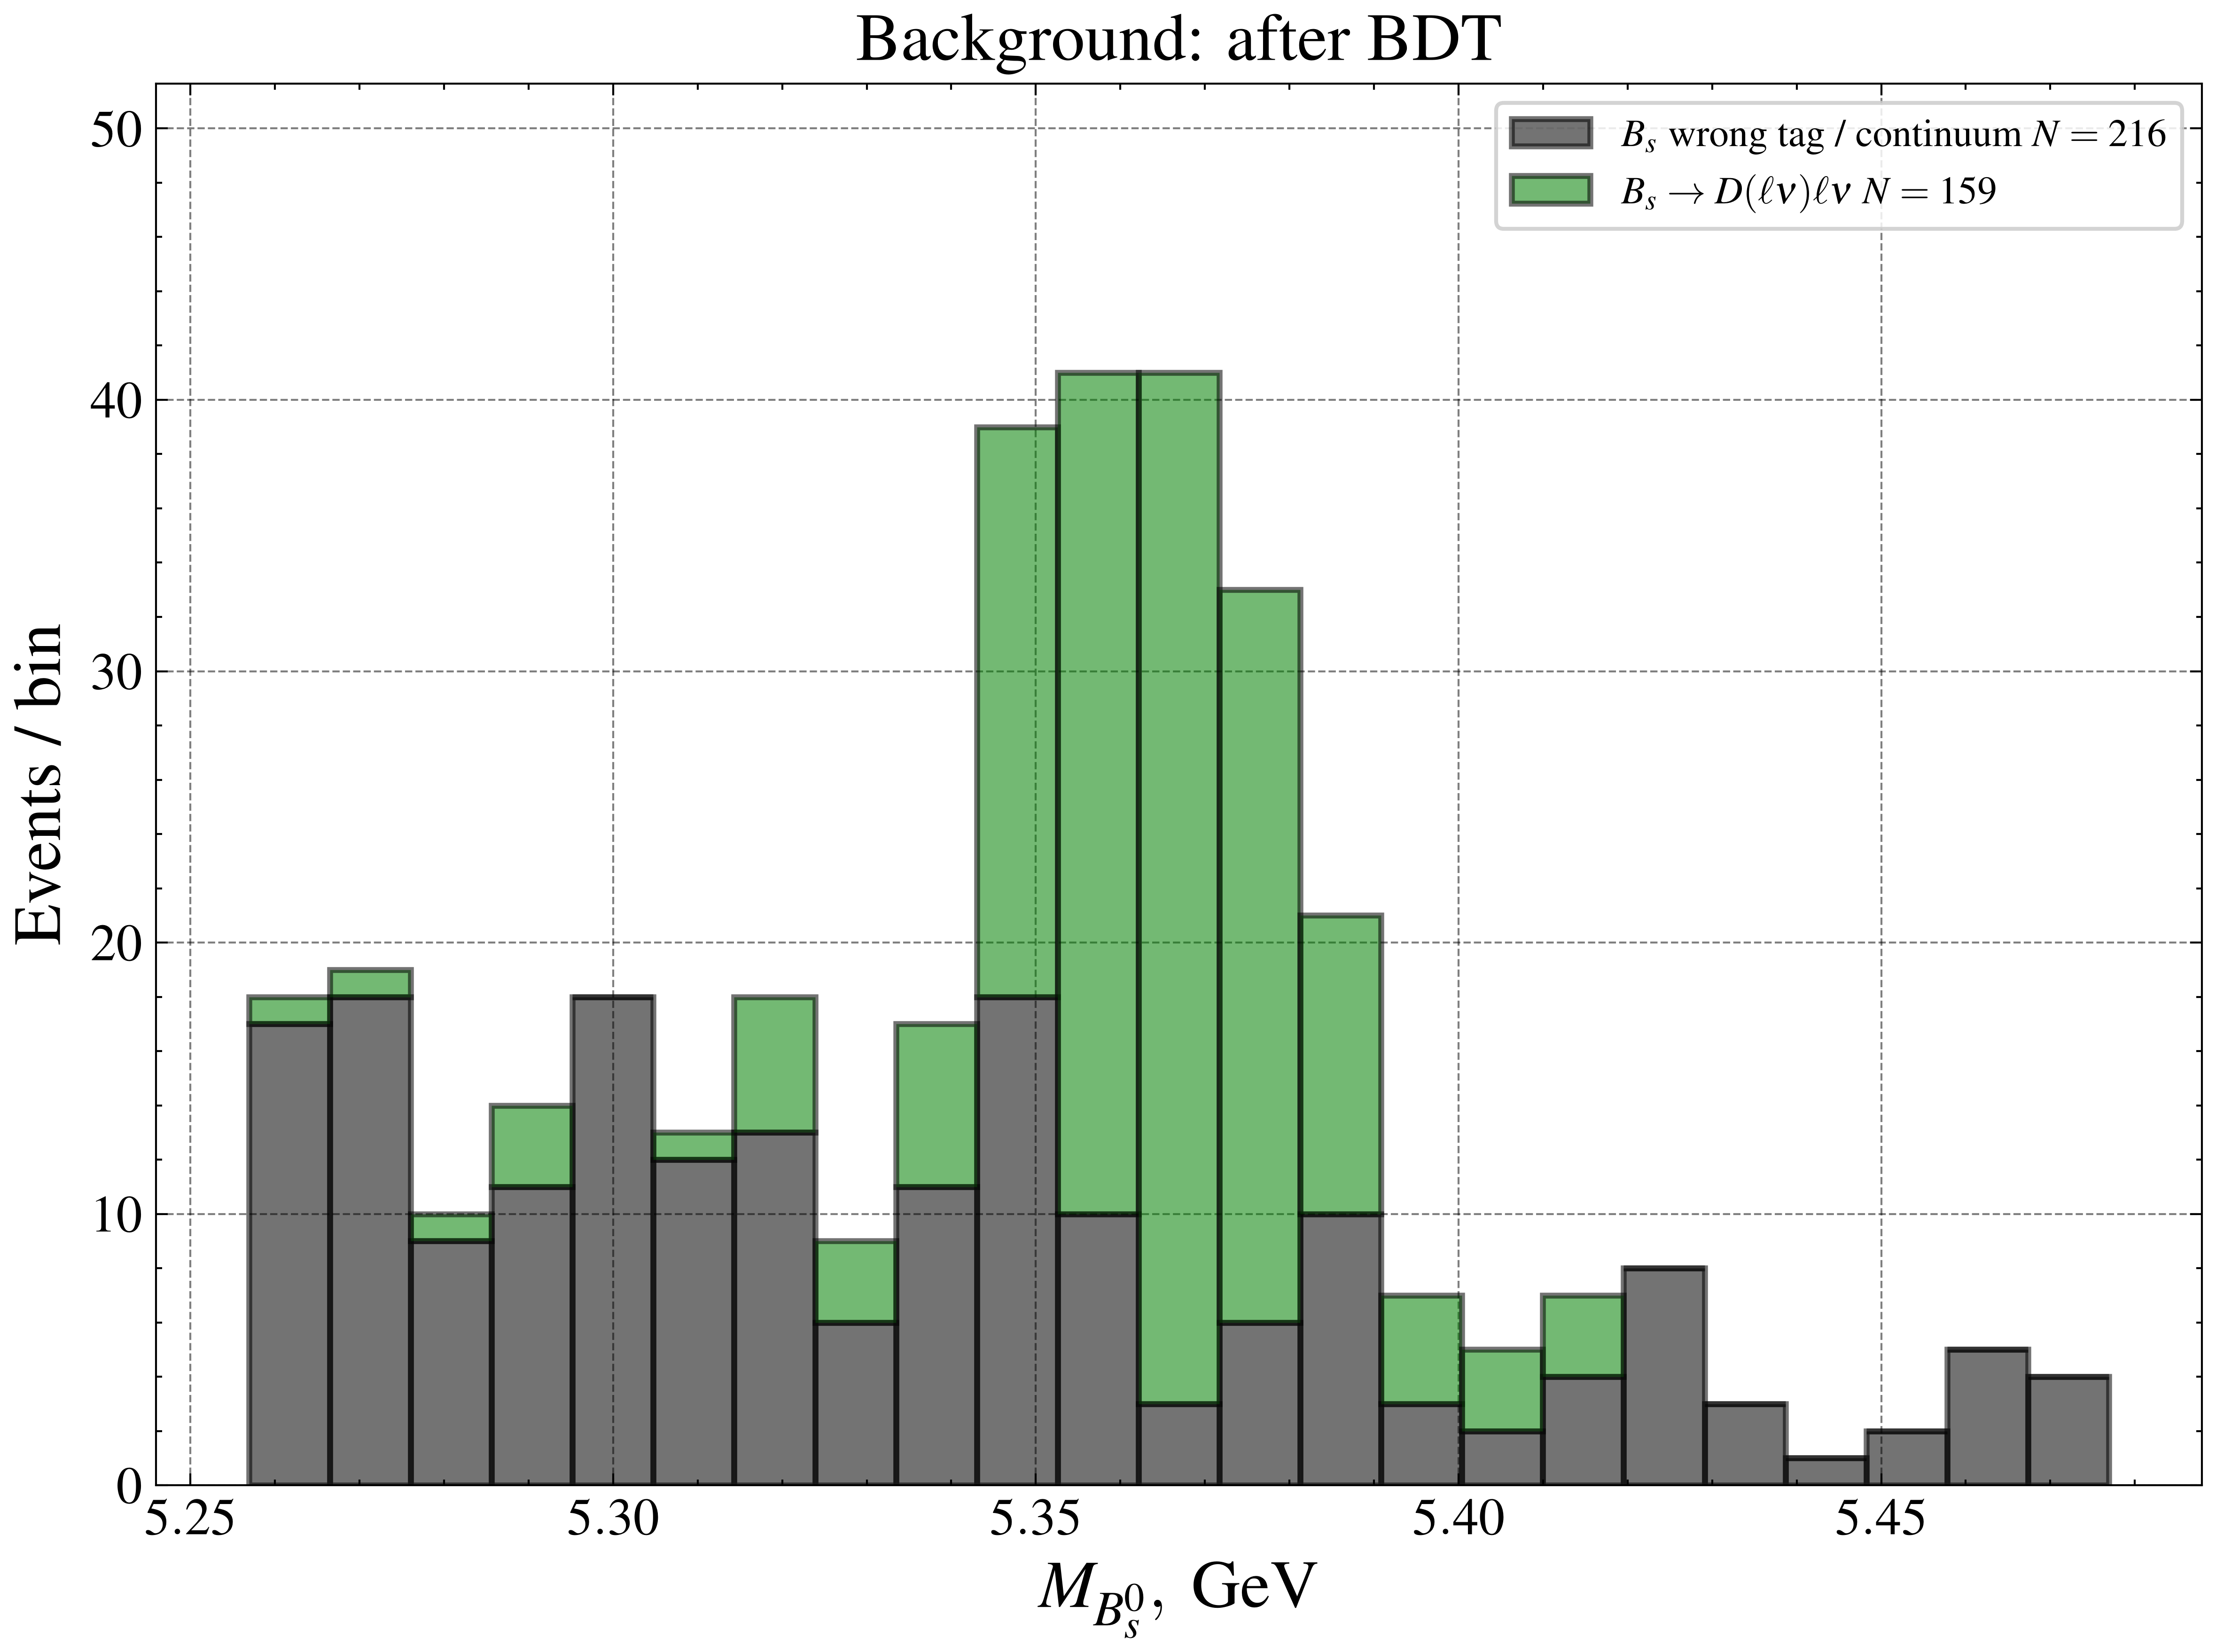

In [36]:
wbin = 0.01
a = Bs_m-0.11
b = Bs_m+0.11
bins = np.linspace(a, b, int((b - a) // wbin) + 2)

stack_data = []
stack_labels = []
for group in background_order:
    subset = selected_data.loc[selected_data["background_group"] == group, "MBtag"]
    stack_data.append(subset)
    stack_labels.append(f"{background_labels[group]} $N = {len(subset)}$")

plt.figure(figsize=(8, 6))
plt.hist(stack_data, bins=bins, stacked=True, alpha=0.55,
         color=[PLOT_COLORS[group] for group in background_order],
         edgecolor="black", linewidth=1.5, label=stack_labels)
plt.xlabel(r"$M_{B_s^0}, \ \mathrm{GeV}$")
plt.ylabel("Events / bin")
plt.title("Background: after BDT")
plt.ylim(top=plt.ylim()[1] * 1.2)
plt.legend(loc="upper right", fontsize=10, framealpha=0.85)
plt.tight_layout()
plt.savefig("output/two_bg_BDT_bg_M_BS0_stack.pdf", dpi=700)
plt.show()


In [37]:
# Количества двух компонент сохранены bg.py вместе с гистограммами.
# Порядок столбцов на stack-графике больше не определяет физические компоненты.
with resources["counts"].open(encoding="utf-8") as f:
    background_counts = json.load(f)
N1 = float(background_counts["N_bg_ubs"])
N2 = float(background_counts["N_bg_bsbs"])
assert np.isclose(N1 + N2, background_counts["N_bg"])


In [38]:
def gen_toy_nd(pdf_func, bounds, size=10000, grid_points=50):
    samples = []

    grids = [np.linspace(a, b, grid_points) for a, b in bounds]
    meshes = np.meshgrid(*grids, indexing='ij')
    Z = pdf_func(meshes)
    ymax = np.max(Z)

    while len(samples) < size:
        x_trial = [np.random.uniform(a, b) for a, b in bounds]
        y_trial = np.random.uniform(0, ymax)

        x_array = [np.array([xi]) for xi in x_trial]

        if y_trial <= pdf_func(x_array):
            samples.append(x_trial)

    return np.array(samples)


In [39]:
# Сигнал задаётся готовой гистограммой после отбора и BDT.
signal_shape = hist_approx().load_hist(str(resources["signal"]))
f_sig = signal_shape.get_pdf


In [40]:
bsbs = hist_approx().load_hist(str(resources["bsbs"]))
ubs = hist_approx().load_hist(str(resources["ubs"]))


In [41]:
toy_pdf = lambda x: bsbs.get_pdf(x)*N2/(N1+N2) + ubs.get_pdf(x)*N1/(N1+N2)
ds_toy = gen_toy_nd(toy_pdf, bounds=[[0, 1.2], [5.25, 5.5]], size=int((N1+N2)/6), grid_points=100)


In [42]:
wbin_x, a_x, b_x = 0.1, 0, 1.2
wbin_y, a_y, b_y = 0.01, 5.25, 5.5
bins_x = np.linspace(a_x, b_x, int((b_x - a_x) // wbin_x))
bins_y = np.linspace(a_y, b_y, int((b_y - a_y) // wbin_y))
bin_centers = [0.5 * (b[:-1] + b[1:]) for b in (bins_x, bins_y)]
bin_centers = np.meshgrid(*bin_centers, indexing='ij')


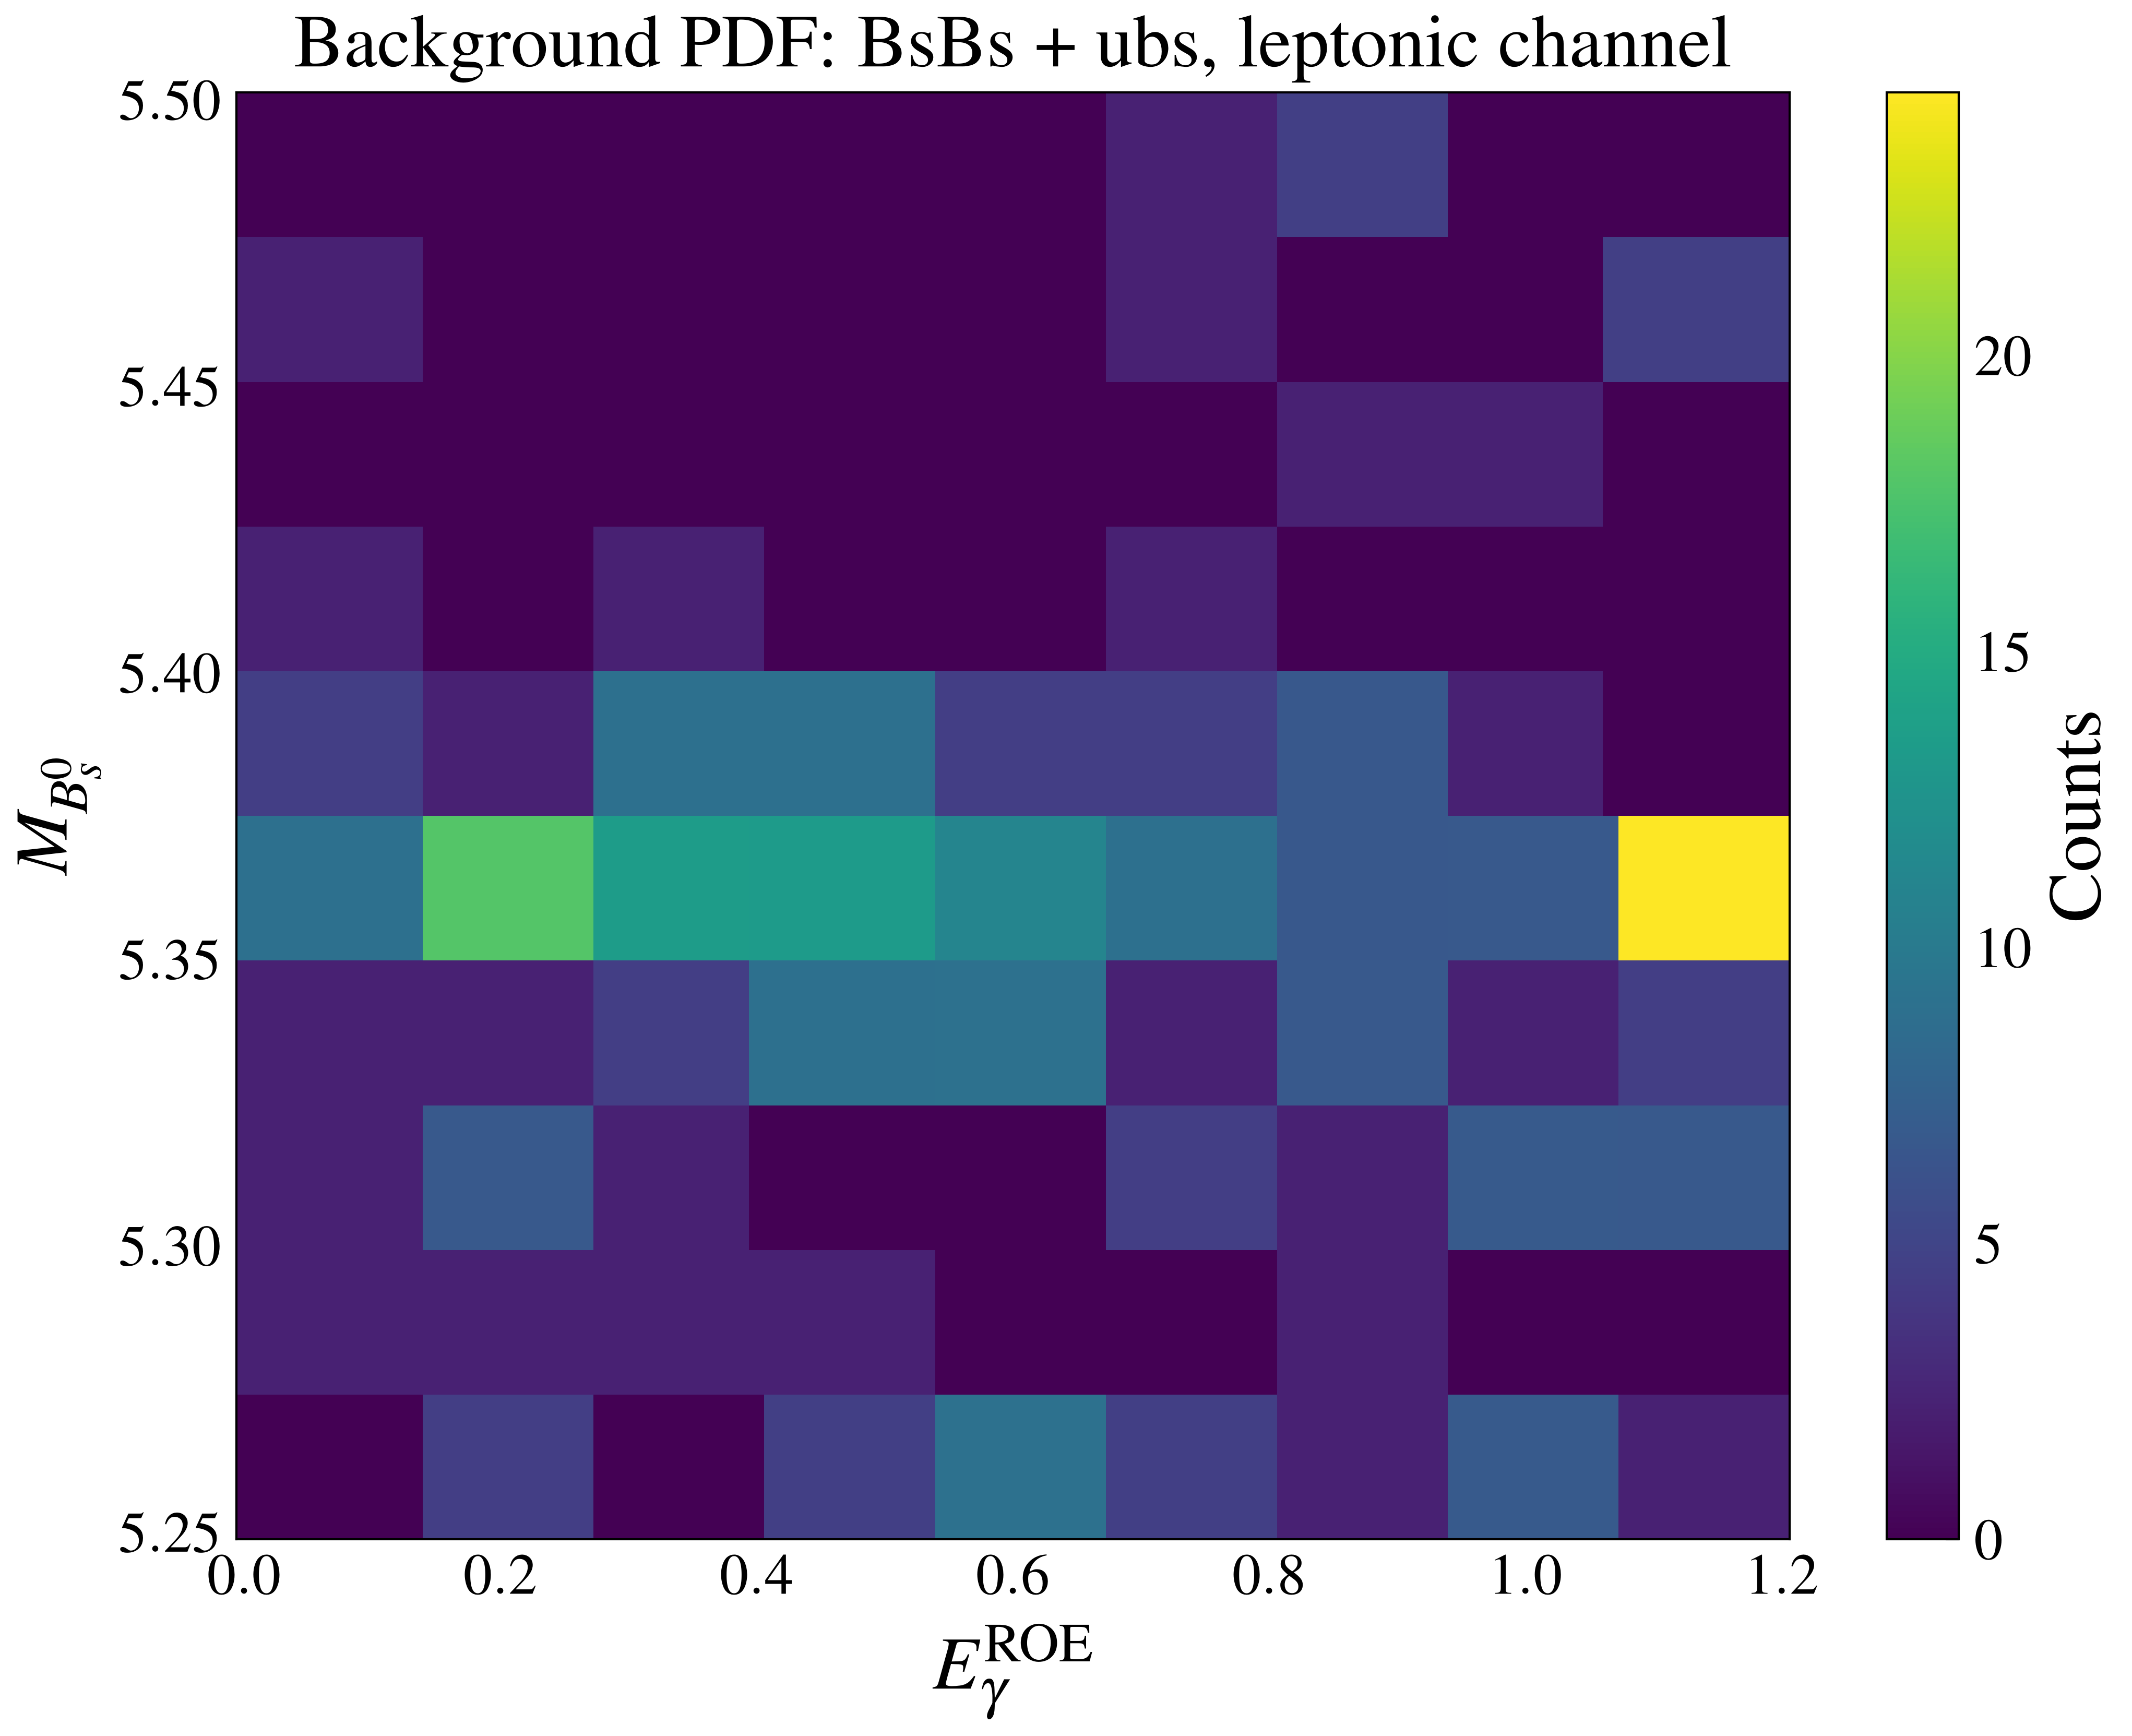

In [43]:
x = np.linspace(a_x, b_x, 100)
y = np.linspace(a_y, b_y, 100)
X, Y = np.meshgrid(x, y, indexing='ij')
val = toy_pdf([X, Y])

plt.figure(figsize=(8, 6))
pmesh = plt.pcolormesh(X, Y, val)
plt.xlabel(r"$E_\gamma^{\mathrm{ROE}}$")
plt.ylabel(r"$M_{B_s^0}$")
plt.title("Background PDF: BsBs + ubs, leptonic channel")
plt.colorbar(pmesh, label="Counts")
plt.show()


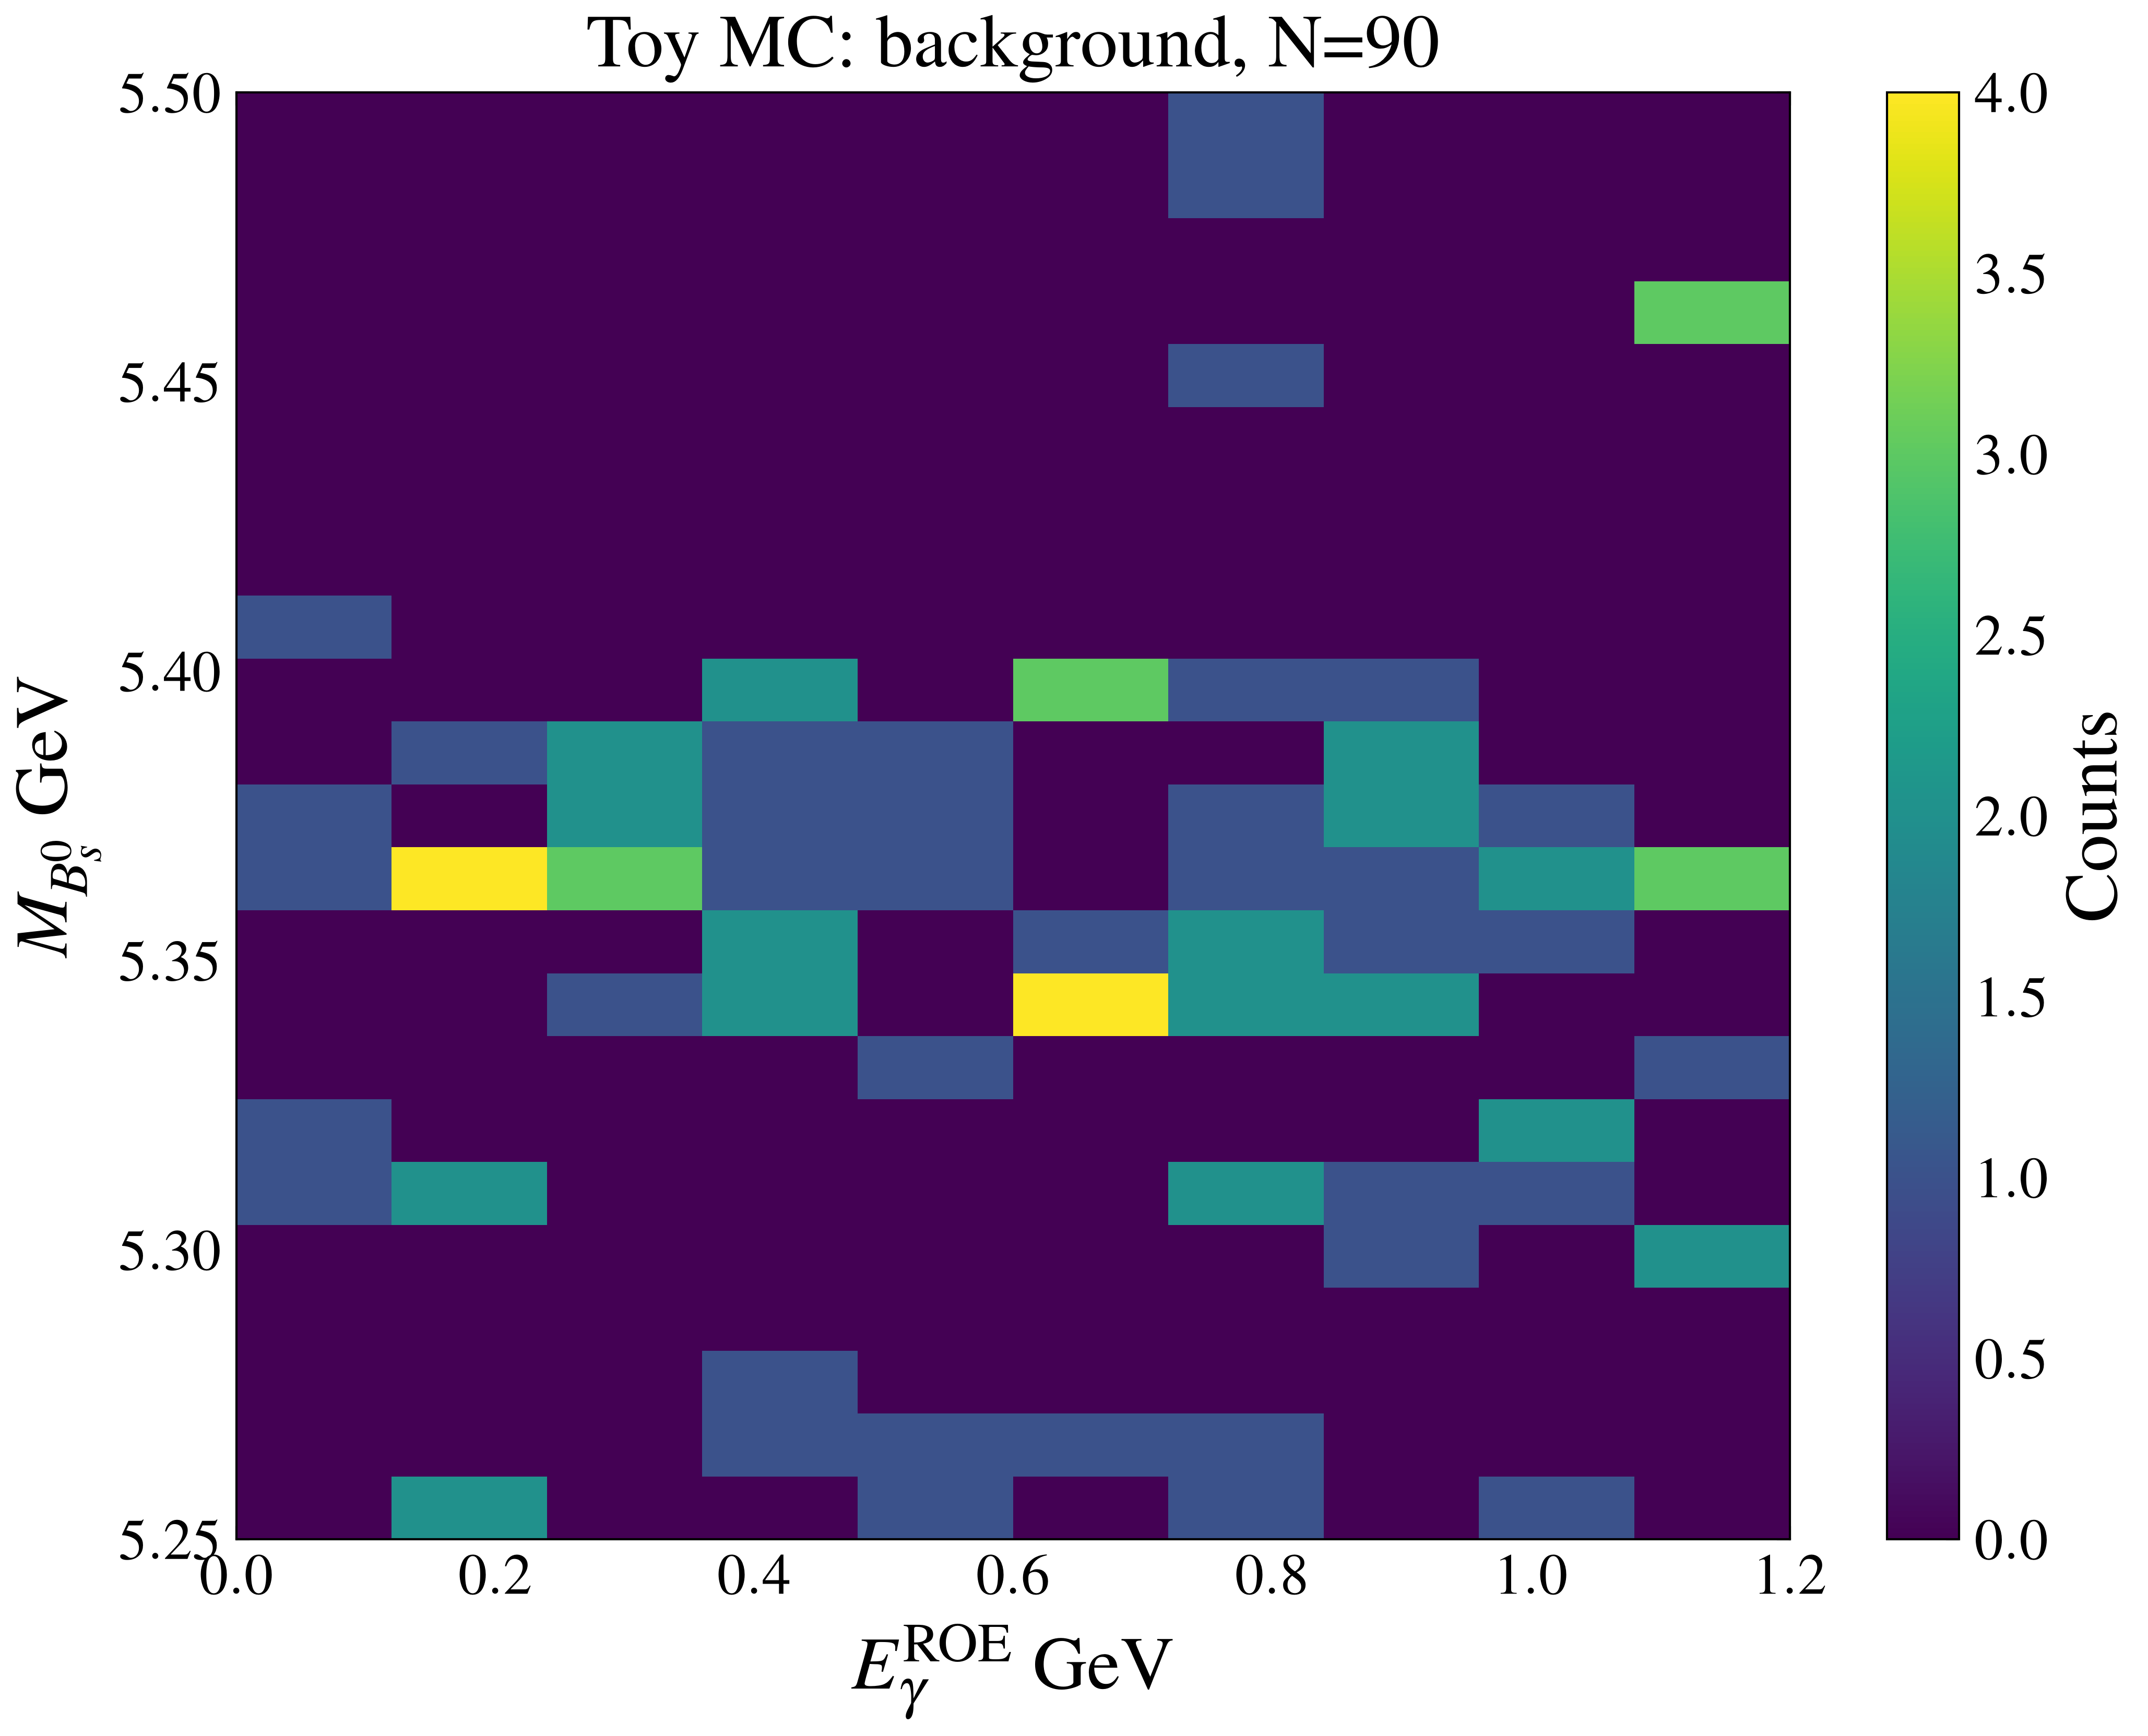

In [44]:
plt.figure(figsize=(8, 6))

h_sig = plt.hist2d(*ds_toy.T, bins=[bins_x, bins_y])

plt.xlabel(r"$E_\gamma^{\mathrm{ROE}} \ \mathrm{GeV}$")
plt.ylabel(r"$M_{B_s^0} \ \mathrm{GeV}$")
plt.title(f"Toy MC: background, N={int((N1+N2)/6)}")
plt.colorbar(h_sig[3], label='Counts')
plt.savefig("output/two_bg_toy_mc_hist2d.pdf", dpi=700)


In [45]:
def f_fit (x, *, N_sig, N_bsbs, N_ubs, stak = False):
    if not stak:
        return (f_sig(x)*N_sig + bsbs.get_pdf(x)*N_bsbs + ubs.get_pdf(x)*N_ubs)/(N_sig + N_bsbs + N_ubs)
    return f_sig(x)*N_sig, bsbs.get_pdf(x)*N_bsbs, ubs.get_pdf(x)*N_ubs


In [46]:
def max_lik_ext(f, x, args0, a=0, b=0, bounds=None, err_need=False):
    
    from scipy.special import factorial
    from numpy import log, exp, power, pi, e
    from numpy import sum as summ
    def poisson(x, n):
        if n > 100:
            return exp(-x)*power(e*x/n, n)/(2*pi*n)
        return exp(-x)*power(x, n)*power(factorial(n), -1)
    
    
    if a == b:
        def df(*args):
            current_args = {k: v for k, v in zip(args0.keys(), args)}
            N_args = sum([v for k, v in current_args.items() if k[0] == "N"])
            return -2*(summ(log(f(x, **current_args)))) - 2*log(poisson(len(x.T),  N_args))
    else:
        def df(*args):
            current_args = {k: v for k, v in zip(args0.keys(), args)}
            N_args = sum([v for k, v in current_args.items() if k[0] == "N"])
            return -2*(summ(log(f(x, **current_args)/normalization(lambda x: f(x.T, **current_args), a, b, func=True, n_points=300)))) - 2*log(poisson(len(x.T), N_args))

    from iminuit import Minuit
    minuit = Minuit(df, *[args0[k] for k in args0], name=list(args0.keys()))

    if bounds:
        for k, bnd in bounds.items():
            minuit.limits[k] = bnd

    minuit.migrad()

    rez = minuit.values.to_dict()
    errs = minuit.errors.to_dict() if err_need else None

    if err_need:
        return {k: v for k, v in rez.items() if k != "norm"}, errs
    return {k: v for k, v in rez.items() if k != "norm"}


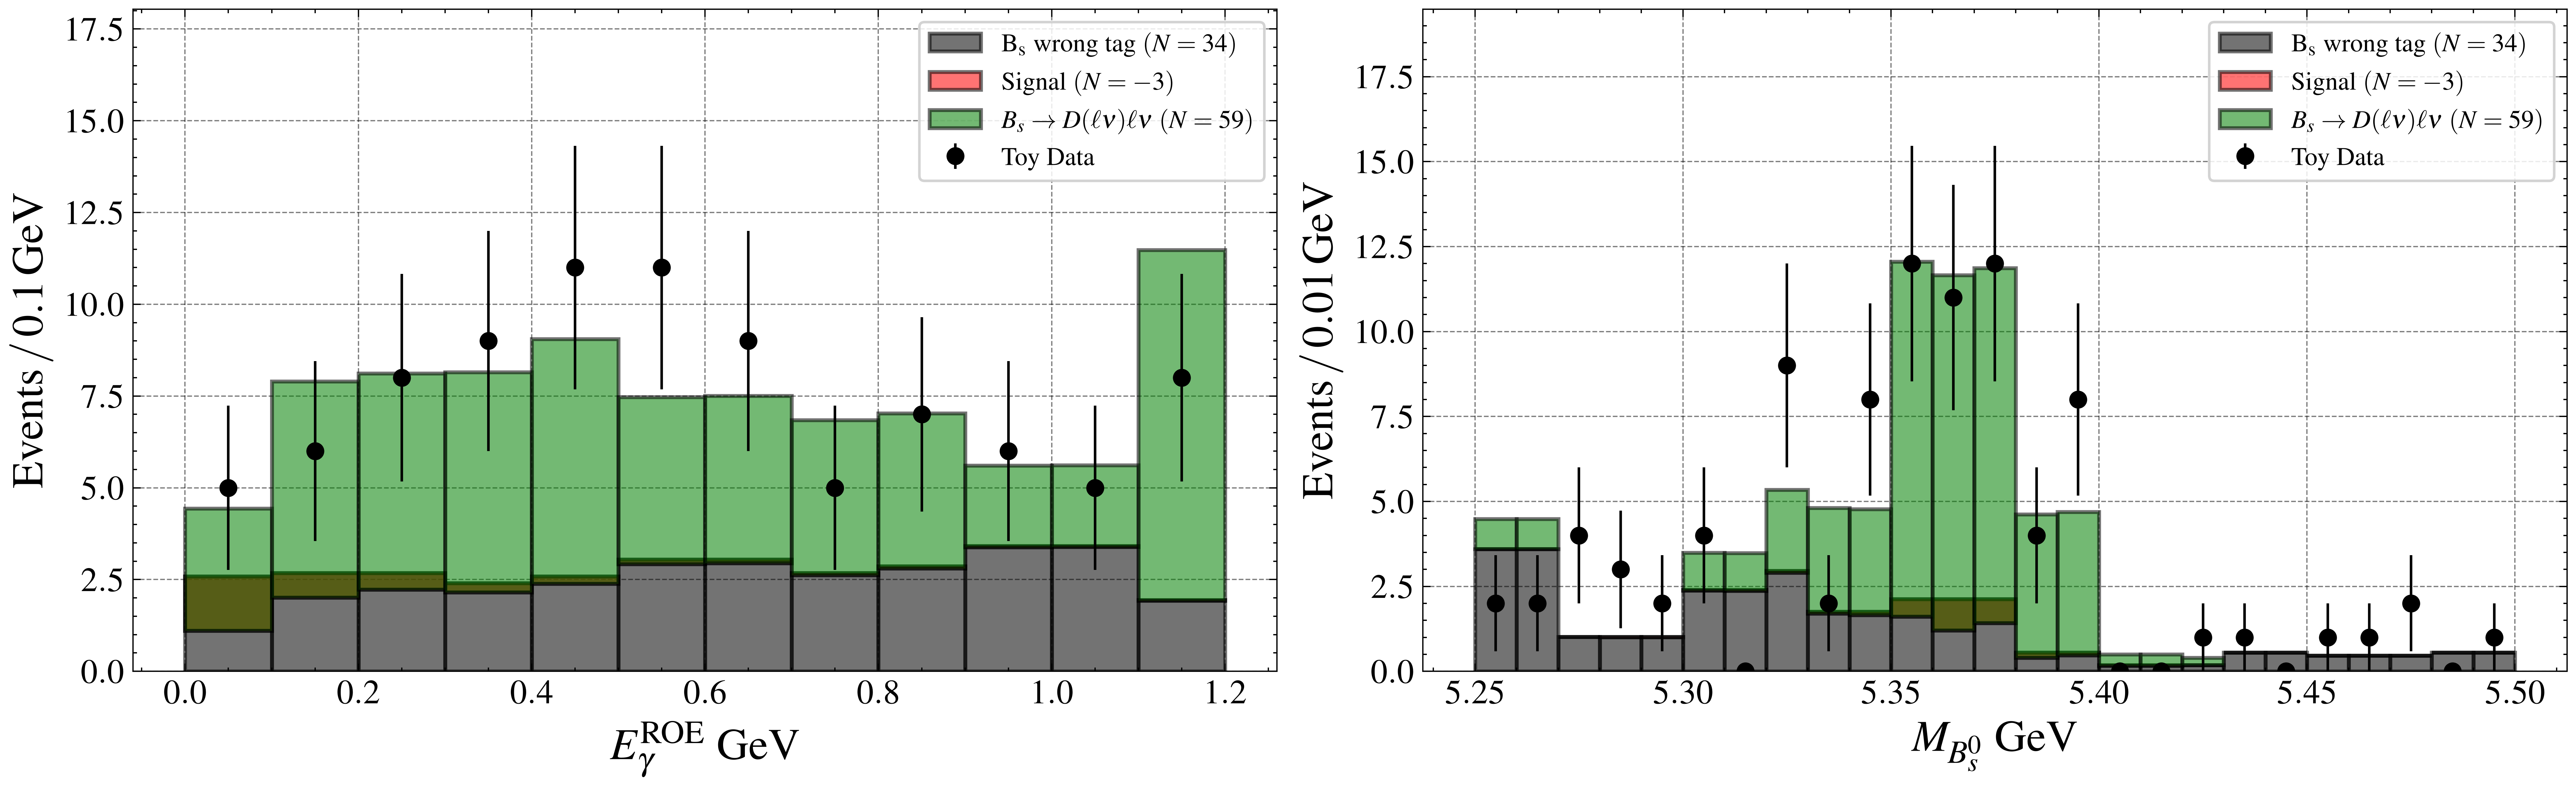

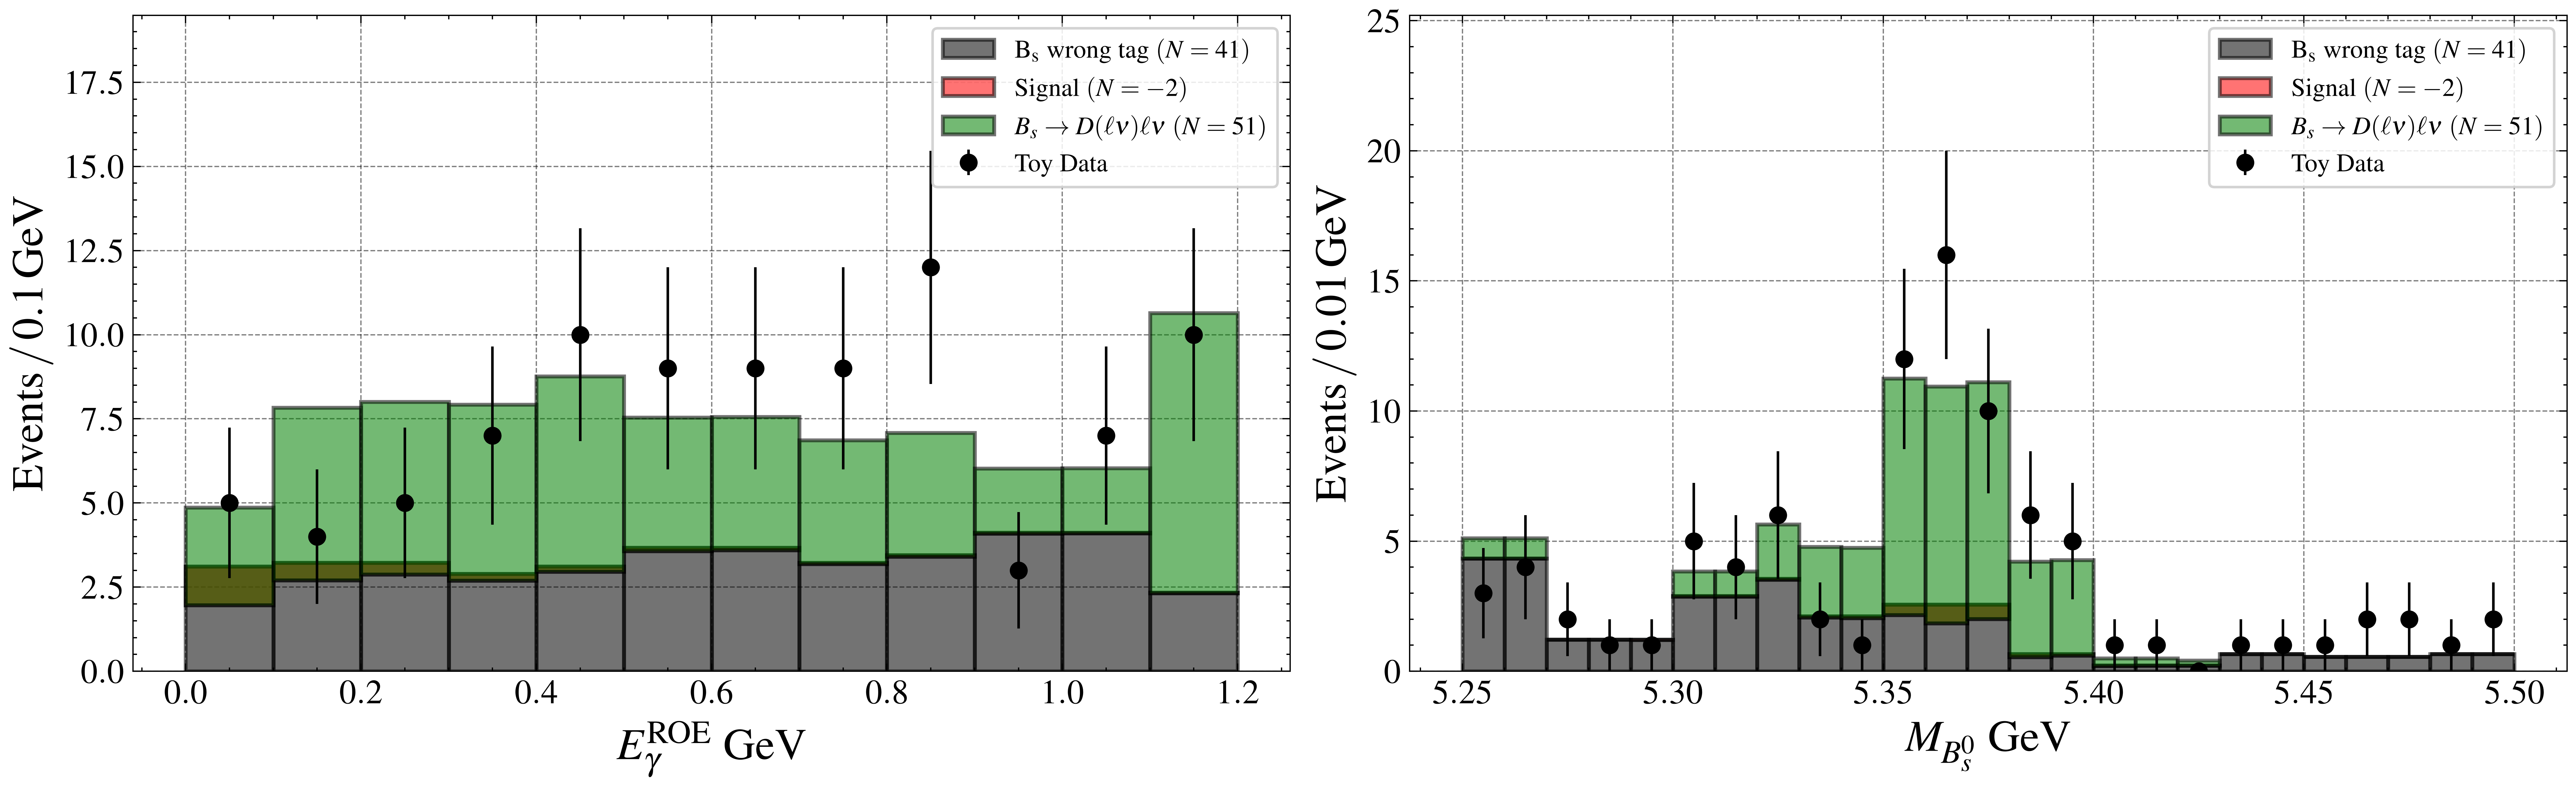

C:\Users\matve\AppData\Local\Temp\ipykernel_2988\2942710718.py:16: RuntimeWarning: invalid value encountered in log
  return -2*(summ(log(f(x, **current_args)))) - 2*log(poisson(len(x.T),  N_args))


In [47]:
wbin_x, a_x, b_x = 0.1, 0, 1.2
wbin_y, a_y, b_y = 0.01, 5.25, 5.5
bins_x = np.linspace(a_x, b_x, int((b_x - a_x) // wbin_x)+2)
bins_y = np.linspace(a_y, b_y, int((b_y - a_y) // wbin_y)+2)

A_list = []
A_errors = []
plt_s = (12/1.7, 6/1.7)

n_toys = 1000
fit_results = []

for i in range(n_toys):
    toy_sample = gen_toy_nd(
        toy_pdf,
        bounds=[[0, 1.2], [5.25, 5.5]],
        size=int((N1+N2)/6),
        grid_points=100
    )
    
    rez, errors = max_lik_ext(
        f_fit,
        toy_sample.T,
        {"N_sig": 0*(N1+N2)/6, "N_bsbs": 0.5*(N1+N2)/6, "N_ubs": 0.5*(N1+N2)/6},
        bounds={"N_sig": (-(N1+N2)/6, N1+N2), "N_bsbs": (-(N1+N2)/6, N1+N2), "N_ubs": (-(N1+N2)/6, N1+N2)},
        err_need=True
    )

    # Пересчёт в физические A0, A1, A2

    N_signal = rez["N_sig"]
    N_bsbs = rez["N_bsbs"]
    N_ubs = rez["N_ubs"]
    
    fit_results.append(rez)
    A_list.append([N_signal, N_bsbs, N_ubs])
    # Ошибки пересчитываются через производные (пока оставим как для w0, w1)
    A_errors.append([errors.get("N_sig", np.nan), errors.get("N_bsbs", np.nan), errors.get("N_ubs", np.nan)])

    # --- рисование только первых 2 игрушек ---
    if i >= 2:
        continue

    fig, axs = plt.subplots(1, 2, figsize=(2*plt_s[0], plt_s[1]*1.25))
    x_centers = 0.5 * (bins_x[:-1] + bins_x[1:])
    y_centers = 0.5 * (bins_y[:-1] + bins_y[1:])
    X, Y = np.meshgrid(x_centers, y_centers, indexing='ij')

    counts, _ = np.histogram(toy_sample.T[0], bins=bins_x)
    sources = f_fit([X, Y], **rez, stak=True)
    fit_proj_x = [np.trapezoid(src, y_centers, axis=1) * wbin_x for src in sources]

    labels = [
        rf"$\mathrm{{Signal}}\ (N={N_signal:.0f})$",
        rf"$B_s \to D(\ell \nu)\ell \nu\ (N={N_bsbs:.0f})$",
        rf"$\mathrm{{B_s\ wrong \ tag}}\ (N={N_ubs:.0f})$"
    ]

    plot_order = (2, 0, 1)
    fit_colors = [PLOT_COLORS[name] for name in ("ubs", "signal", "bsbs")]
    plot_labels = [labels[j] for j in plot_order]

    ax = axs[0]
    ax.errorbar(x_centers, counts, yerr=np.sqrt(counts), fmt='o', color=PLOT_COLORS["data"], label="Toy Data")
    ax.hist([x_centers]*len(fit_proj_x), bins=bins_x, weights=[fit_proj_x[j] for j in plot_order],
            stacked=True, alpha=0.55, edgecolor="black", linewidth=1.5, color=fit_colors, label=plot_labels)
    ax.set_ylabel(fr'$\mathrm{{Events}}\,/\,{wbin_x}\,\mathrm{{GeV}}$')
    ax.set_xlabel(r'$E_{\gamma}^\mathrm{ROE}\ \mathrm{GeV}$')
    ax.set_ylim(top=ax.get_ylim()[1] * 1.2)
    ax.legend(loc="upper right", fontsize=10, framealpha=0.85)

    counts, _ = np.histogram(toy_sample.T[1], bins=bins_y)
    fit_proj_y = [np.trapezoid(src, x_centers, axis=0) * wbin_y for src in sources]

    ax = axs[1]
    ax.errorbar(y_centers, counts, yerr=np.sqrt(counts), fmt='o', color=PLOT_COLORS["data"], label="Toy Data")
    ax.hist([y_centers]*len(fit_proj_y), bins=bins_y, weights=[fit_proj_y[j] for j in plot_order],
            stacked=True, alpha=0.55, edgecolor="black", linewidth=1.5, color=fit_colors, label=plot_labels)
    ax.set_ylabel(fr'$\mathrm{{Events}}\,/\,{wbin_y}\,\mathrm{{GeV}}$')
    ax.set_xlabel(r'$M_{B_s^0}\ \mathrm{GeV}$')
    ax.set_ylim(top=ax.get_ylim()[1] * 1.2)
    ax.legend(loc="upper right", fontsize=10, framealpha=0.85)

    plt.tight_layout()
    plt.savefig(f"output/two_bg_toy_mc_fit_{i}.pdf")
    plt.show()


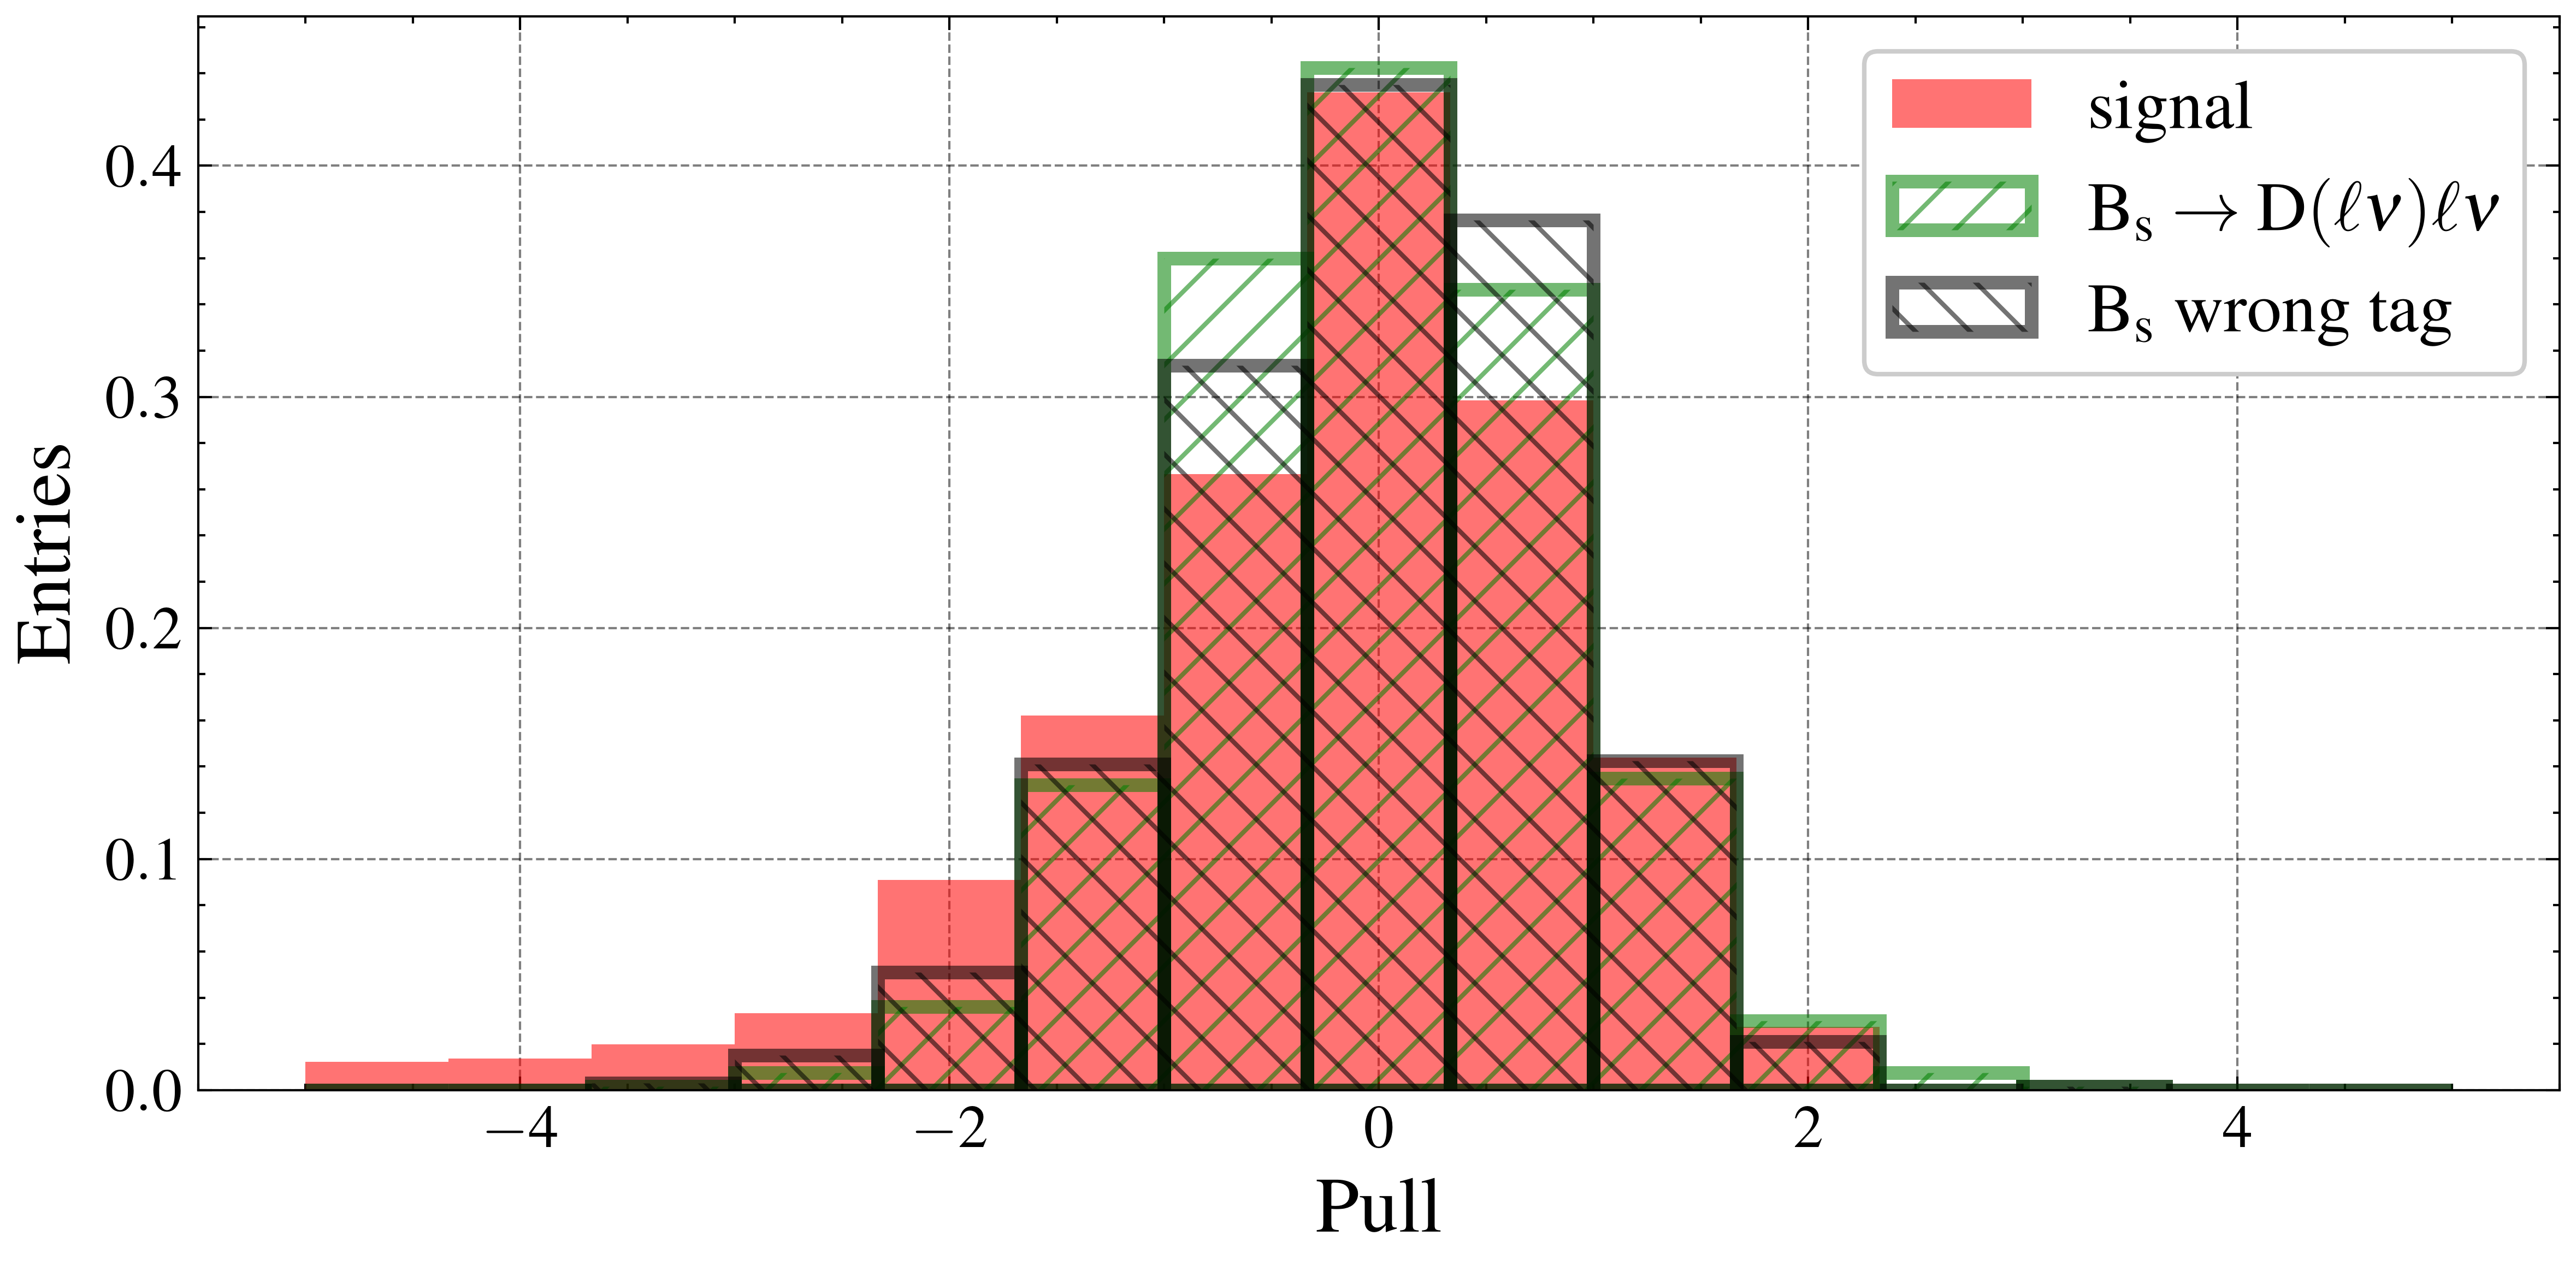

In [48]:
# --- анализ pull ---
A_array = np.array(A_list)
A_errors = np.array(A_errors)
bins = np.linspace(-5, 5, 16)

A0_true = 0
A1_true = N2/6
A2_true = N1/6

delta_signal = (A_array[:, 0] - A0_true) / A_errors[:, 0]
delta_bsb = (A_array[:, 1] - A1_true) / A_errors[:, 1]
delta_ubs = (A_array[:, 2]- A2_true) / A_errors[:, 2] 

counts_signal, bin_edges = np.histogram(delta_signal, bins=bins, density=True)
counts_bsb, _ = np.histogram(delta_bsb, bins=bins, density=True)
counts_ubs, _ = np.histogram(delta_ubs, bins=bins, density=True)

bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.bar(bin_centers, counts_signal, width=np.diff(bins), alpha=0.55, color=PLOT_COLORS["signal"], label=r"$\mathrm{signal}$", align='center')
plt.bar(bin_centers, counts_bsb, width=np.diff(bins), label=r"$\mathrm{B_s \to D(\ell \nu)\ell \nu}$",
        align='center', facecolor='none', edgecolor=PLOT_COLORS["bsbs"], alpha=0.55, hatch='//', linewidth=3)
plt.bar(bin_centers, counts_ubs, width=np.diff(bins), label=r"$\mathrm{B_s \ wrong \ tag}$",
        align='center', facecolor='none', edgecolor=PLOT_COLORS["ubs"], alpha=0.55, hatch='\\\\', linewidth=3)

plt.xlabel(r"$\mathrm{Pull}$")
plt.ylabel(r"$\mathrm{Entries}$")
plt.legend()
plt.tight_layout()
plt.savefig(f"output/two_bg_toy_err.pdf")
plt.show()


In [49]:
(A_array[:, 0]+A_array[:, 1]+A_array[:, 2]) - N2/6 - N1/6


array([-0.50799406, -0.503392  , -0.45102636, -0.49469245, -0.47059498,
       -0.50209179, -0.49995741, -0.48029574, -0.50245903, -0.49896298,
       -0.49755132, -0.50243281, -0.49834281, -0.49054283, -0.4880221 ,
       -0.51753441, -0.50451672, -0.50677443, -0.49939096, -0.49926247,
       -0.45926663, -0.49762491, -0.50360304, -0.50149081, -0.52064951,
       -0.49809638, -0.51742414, -0.49894496, -0.5292781 , -0.45290767,
       -0.51080831, -0.47985204, -0.50125533, -0.51312528, -0.50006842,
       -0.50223487, -0.4950807 , -0.46393084, -0.49737655, -0.50028284,
       -0.53236963, -0.48662521, -0.47353989, -0.50099075, -0.50069956,
       -0.49298767, -0.49739758, -0.48783865, -0.48568721, -0.49088146,
       -0.50144214, -0.50784568, -0.51030996, -0.49582681, -0.49921993,
       -0.50126262, -0.50566852, -0.51740806, -0.5139804 , -0.49917715,
       -0.54578338, -0.48703314, -0.49774236, -0.49988128, -0.50883844,
       -0.50411566, -0.50676618, -0.51914758, -0.49003949, -0.49

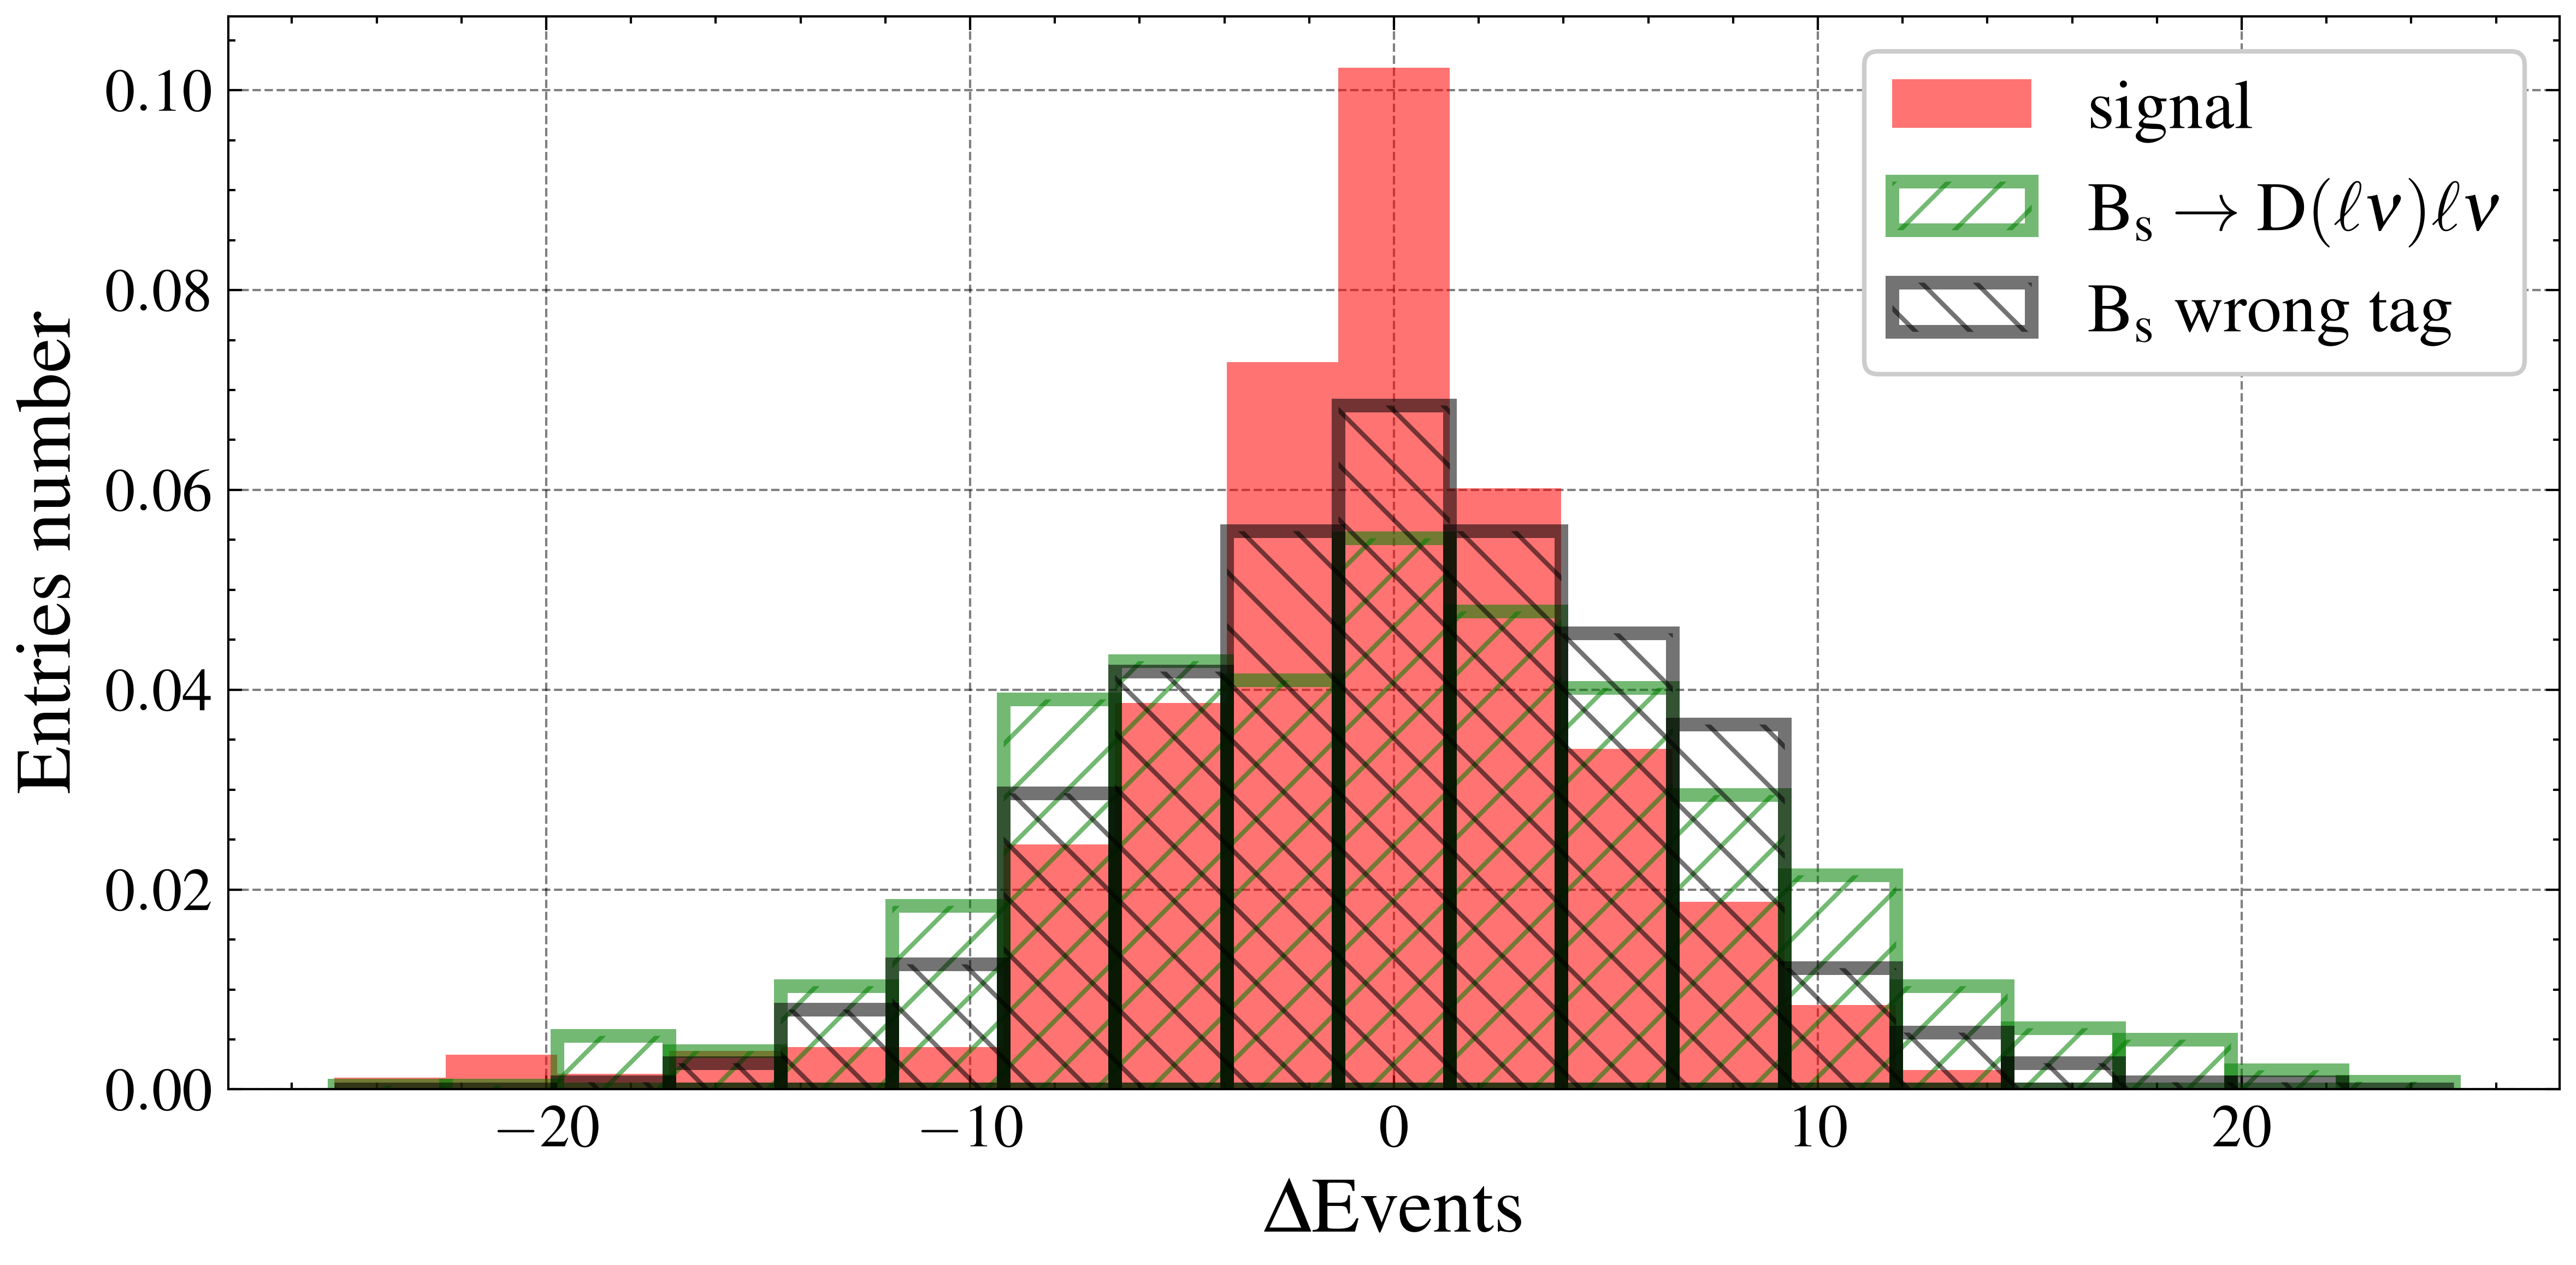

In [50]:
# --- анализ pull ---
A_array = np.array(A_list)
A_errors = np.array(A_errors)
bins = np.linspace(-25, 25, 20)

A0_true = 0
A1_true = N2/6
A2_true = N1/6

delta_signal = (A_array[:, 0] - A0_true)
delta_bsb = (A_array[:, 1] - A1_true)
delta_ubs = (A_array[:, 2]- A2_true)

counts_signal, bin_edges = np.histogram(delta_signal, bins=bins, density=True)
counts_bsb, _ = np.histogram(delta_bsb, bins=bins, density=True)
counts_ubs, _ = np.histogram(delta_ubs, bins=bins, density=True)

bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.bar(bin_centers, counts_signal, width=np.diff(bins), alpha=0.55, color=PLOT_COLORS["signal"], label=r"$\mathrm{signal}$", align='center')
plt.bar(bin_centers, counts_bsb, width=np.diff(bins), label=r"$\mathrm{B_s \to D(\ell \nu)\ell \nu}$",
        align='center', facecolor='none', edgecolor=PLOT_COLORS["bsbs"], alpha=0.55, hatch='//', linewidth=3)
plt.bar(bin_centers, counts_ubs, width=np.diff(bins), label=r"$\mathrm{B_s \ wrong \ tag}$",
        align='center', facecolor='none', edgecolor=PLOT_COLORS["ubs"], alpha=0.55, hatch='\\\\', linewidth=3)

plt.xlabel(r"$\mathrm{\Delta Events}$")
plt.ylabel(r"$\mathrm{Entries \ number}$")
plt.legend()
plt.tight_layout()
plt.savefig(f"output/two_bg_toy_delta.pdf")
plt.show()


In [51]:
f_n_sig = (A_array[:, 0])
delta_signal = np.sort(A_array[:, 0])[int(len(f_n_sig)*0.95)]
print(delta_signal)


7.856024220857364


In [52]:
print(np.mean(A_array[:, 0]))


-0.9410828446788662
